# MNIST orthogonal class-dependent batch effect
## 1. Purpose / experiment definition
Two distinct, exactly class-balanced MNIST batches receive class-dependent perturbations in
orthogonal trailing-PC subspaces, with independent scale permutations in each batch.
Original pixels are the main experiment; signal-projected pixels provide the exact invariance control.
There is no observation pairing across batches.

Scientific construction and experiment loops are visible below. Existing library methods perform
OT, embeddings, scoring, strict artifact I/O, and manuscript drawing. Fixed ε and signal projection remain mechanism controls; extra rel_reg settings remain ablations.
MultiMAP is intentionally simplified to native defaults or k=15, as requested; the previous
controlled hyperparameters and preprocessing grid are no longer used for new runs.

Use the project Python environment (with the dependencies in `pyproject.toml`). Execute in order.
The full grid is expensive; the configuration cell gives an explicit smoke override.

## 2. Imports and global configuration
Change scientific parameters once here. Compute mode creates/resumes the deterministic named run;
load mode requires that exact compatible completed run. No latest-run discovery occurs.
MNIST downloading is opt-in. MultiMAP uses the repository's configured external environment.
The `SyntheticExperiment` object below stores state and supplies shared artifact/graph utilities;
its high-level experiment execution methods are deliberately not called.
Fresh ε₀ ablation: schedule values come from configs/benchmark.toml; λ=0 is also evaluated
for embeddings. No legacy iteration schedule or embedding cache is selected.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from ne_aligned_utils import paper
from ne_aligned_utils.experiments.synthetic import (
    build_mnist_construction,
    compare_construction,
    CompetitorsConfig,
    CorruptionConfig,
    DataConfig,
    EmbeddingConfig,
    EvaluationConfig,
    ExperimentConfig,
    ExperimentPaths,
    OtConfig,
    SyntheticExperiment,
)
from ne_aligned_utils.paper.inputs import synthetic as saved_synthetic
from ne_aligned_utils.paper.figures.synthetic import build_variant

paper.use_paper_style()
import json
from functools import partial
from sklearn.decomposition import PCA
from torchvision.datasets import MNIST
from ne_aligned_utils.evaluation.metrics import compute_kbet, compute_neighbor_purity
from ne_aligned_utils.methods import (
    compute_ot_plan,
    compute_ot_tsne_embedding_from_plan,
    compute_scanorama_then_tsne_embedding_from_arrays,
)
from ne_aligned_utils.methods.external.multimap import compute_multimap_embedding_from_arrays
from ne_aligned_utils.experiments.synthetic import label_methods
from dataclasses import dataclass
from types import SimpleNamespace
from ne_aligned_utils.paper import layout, registry
from ne_aligned_utils.paper.figures import synthetic as drawing
from dataclasses import asdict, replace
from ne_aligned_utils.methods import compute_tsne_embedding_from_arrays


.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Fresh output namespace; construction source is explicit and read-only.
import tomllib
import hashlib
import subprocess
benchmark_definition = tomllib.loads((ROOT / "configs/benchmark.toml").read_text())
benchmark_settings = benchmark_definition["settings"]
TSNE_N_JOBS = int(benchmark_definition["resources"]["cpu"]["threads"])
SOURCE_RUN_DIR = ROOT / "data/mnist/orthogonal"  # recorded batch construction of the paper's run
source_manifest = json.loads((SOURCE_RUN_DIR / "config.json").read_text())
source_construction = SOURCE_RUN_DIR / "data/construction.npz"
source_audit = pd.read_csv(SOURCE_RUN_DIR / "original/diagnostics/corruption_audit.csv")
# Execution paths; MNIST must exist unless download_mnist=True.
RUN_EXPERIMENT = False
# Loading reads the run this configuration produces; compute it once with RUN_EXPERIMENT = True.
RUN_NAME = None
SAVE_PAPER_FIGURE = False
RESUME_ABLATION = False  # True resumes only this new run; old runs are never used for outputs.
# MNIST is read from this checkout's data/torchvision (or data/).
SOURCE_ROOT = ROOT
print(f"MNIST source checkout: {SOURCE_ROOT}")

config = ExperimentConfig(
    data=DataConfig(
        random_seed=0,
        n_per_digit=100,
        signal_variance_target=0.90,
        signal_rank=None,
        tail_pool_size=30,
        tail_variance_rel_tol=1e-10,
        tail_pca_indices=None,
        modes=("original", "projected"),
    ),
    corruption=CorruptionConfig(
        magnitudes=(0.0, 1.0, 4.0, 10.0, 20.0),
        corruption_seeds=(0, 1, 2),
        class_corruption_scales=tuple(np.linspace(0.35, 2.60, 10)),
        batch1_seed_offset=10_000,
        batch0_scale_seed_offset=20_000,
        batch1_scale_seed_offset=30_000,
    ),
    ot=OtConfig(
        epsilon_policies=("fixed_at_lambda_0", "adaptive_per_magnitude"),
        rel_reg=(1.0,),
        ot_effective_k=15,
        ot_tol=1e-12,
        ot_max_iter=10_000,
    ),
    competitors=CompetitorsConfig(
        cross_batch_k=15, run_multimap=True, run_scanorama_50_tsne=True, multimap_profile="default"
    ),
    # t-SNE schedule: 250 exaggerated + 500 iterations (openTSNE's defaults, as in the benchmark).
    embedding=EmbeddingConfig(
        embedding_seeds=(0, 1, 2), n_epochs=benchmark_settings["visualization_epochs"],
        early_exaggeration_iter=benchmark_settings["tsne_early_exaggeration_iter"]
    ),
    evaluation=EvaluationConfig(kbet_k=15),
)
# Optional smoke grid: enable explicitly; these results are not manuscript estimates.
# Batches when RUN_EXPERIMENT: False loads the recorded construction above. True samples
# MNIST (downloading it into data/torchvision when missing), fits the PCA, and checks both
# against the recorded construction.
BUILD_FROM_MNIST = False
SMOKE = False
if SMOKE:
    from dataclasses import replace

    config = replace(
        config,
        data=replace(config.data, n_per_digit=10),
        corruption=replace(config.corruption, magnitudes=(0.0, 1.0, 10.0), corruption_seeds=(0,)),
        competitors=replace(config.competitors),
        embedding=replace(config.embedding, embedding_seeds=(0,), n_epochs=10, early_exaggeration_iter=10),
    )
mnist_root = SOURCE_ROOT / "data/torchvision"
if not (mnist_root / "MNIST/raw").is_dir() and (SOURCE_ROOT / "data/MNIST/raw").is_dir():
    mnist_root = SOURCE_ROOT / "data"
paths = ExperimentPaths(
    # Quick-mode runs go to their own folder, so a full run never reads them.
    results_root=ROOT / "results/synthetic_eps_ablation" / ("smoke-v2" if SMOKE else "benchmark-defaults-eps0-20261108-v2"),
    data_root=mnist_root, run_name=RUN_NAME, download_mnist=BUILD_FROM_MNIST
)
experiment = SyntheticExperiment(config, paths)
print("Experiment: MNIST orthogonal class-dependent batch effect")
print("Input representations: original pixels; signal-projected pixels")
print(f"Run: {experiment.run_dir.name}\nResults: {experiment.run_dir}")
print(f"Figure output (when enabled): {ROOT / 'results/paper_figures/synthetic_experiment/final'}")
if RUN_EXPERIMENT and experiment.run_dir.exists() and not RESUME_ABLATION:
    raise FileExistsError(f"Fresh run already exists: {experiment.run_dir}. "
                          "Explicitly set RESUME_ABLATION=True or load the saved run.")
if not SMOKE:
    for section in ("data", "corruption"):
        requested = json.loads(json.dumps(asdict(config)[section]))
        recorded = source_manifest["config"][section].copy()
        if section == "corruption":
            assert set(requested.pop("magnitudes")) == {0.0, *recorded.pop("magnitudes")}
        assert requested == recorded, f"Construction settings changed: {section}"
print(f"Ablation outputs: {experiment.run_dir}")
print(f"openTSNE schedule: {config.embedding.early_exaggeration_iter} + {config.embedding.n_epochs}")

def load_selected_ablation(selected_experiment=experiment, expected_run_dir=experiment.run_dir):
    """Load only the run selected above; diagnose stale notebook state before file I/O."""
    if experiment is not selected_experiment or experiment.run_dir != expected_run_dir:
        raise RuntimeError(
            "The experiment object no longer matches this notebook's configuration. "
            "Restart the kernel and Run All, or rerun the imports and configuration cells.")
    manifest_path = expected_run_dir / "config.json"
    if not manifest_path.is_file():
        raise FileNotFoundError(
            f"Selected saved ablation is missing: {manifest_path}. "
            "Check RUN_NAME and the v2 results root in the configuration cell. "
            "Restart the kernel and Run All if an older results path appears. "
            "To compute the run instead, set RUN_EXPERIMENT = True (SMOKE = True for a quick check).")
    return selected_experiment.load_saved()


if not RUN_EXPERIMENT:
    runs = load_selected_ablation()  # checks exact configuration; no MNIST/PCA/method execution
    print("Loaded compatible saved artifacts.")


# Diagnostic selection only; these values do not change the saved experiment grid.
@dataclass(frozen=True)
class DiagnosticConfig:
    magnitude: float = 10.0
    corruption_seed: int = 0
    rel_reg: float = 1.0
    mode: str = "original"


plot_config = DiagnosticConfig()  # choose λ here for the 10-digit clean/noisy grid

MNIST source checkout: .
Experiment: MNIST orthogonal class-dependent batch effect
Input representations: original pixels; signal-projected pixels
Run: mnist_orthogonal_batch_effect__seed0__c70fb5e4
Results: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__c70fb5e4
Figure output (when enabled): results/paper_figures/synthetic_experiment/final
Ablation outputs: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__c70fb5e4
openTSNE schedule: 250 + 500
Loaded compatible saved artifacts.


In [4]:
# Reuse only this session's newly fitted native MultiMAP outputs, whose settings are unchanged.
# Every t-SNE-based output is recomputed with the benchmark's four workers in the v2 namespace.
import shutil
REUSE_FRESH_NATIVE_FITS = False  # Only enable for an explicit resource-only refresh.
if RUN_EXPERIMENT and not SMOKE and REUSE_FRESH_NATIVE_FITS:
    current_fits = (ROOT / "results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v1"
                    / experiment.run_dir.parent.name / experiment.run_dir.name)
    fitted_provenance = json.loads((current_fits / "ablation_manifest.json").read_text())
    assert fitted_provenance["benchmark_settings"] == benchmark_settings
    assert fitted_provenance["source_construction_sha256"] == hashlib.sha256(source_construction.read_bytes()).hexdigest()
    for source in current_fits.glob("*/embeddings/multimap*/*/*/*"):
        if source.is_file() and source.suffix in {".npz", ".json"}:
            target = experiment.run_dir / source.relative_to(current_fits)
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, target)
    source_plans = current_fits / "ablation/ot_plans"
    if source_plans.is_dir():
        shutil.copytree(source_plans, experiment.run_dir / "ablation/ot_plans", dirs_exist_ok=True)
    (experiment.run_dir / "benchmark_resource_refresh.json").write_text(json.dumps(dict(
        tsne_n_jobs=TSNE_N_JOBS, reused_fresh_multimap_from=str(current_fits),
        reason="Only t-SNE worker count changed; native MultiMAP and solver inputs/settings are identical"), indent=2))
    print(f"Benchmark openTSNE workers: {TSNE_N_JOBS}; fresh native MultiMAP fits retained from {current_fits.name}")

In [5]:
# Notebook-local cache: only the new rerun's plans are eligible; no legacy method-output reuse.
import hashlib
import time
from ne_aligned_utils.methods import compute_ot_plan
from ne_aligned_utils.methods.ot_affinity import (
    BlockScores, select_four_block, graph_from_pairs,
)

PLAN_TV_ATOL = 1e-7  # Declared comparison tolerance, distinct from Sinkhorn's stop threshold.
plan_directory = experiment.run_dir / "ablation/ot_plans"

if not RUN_EXPERIMENT:
    baseline_eps = runs.cost.loc[(runs.cost.magnitude == 0) &
                                 (runs.cost.epsilon_policy == "fixed_at_lambda_0")]
    experiment.reference_epsilons = {mode: {float(reg): float(part.epsilon.iloc[0])
        for reg, part in group.groupby("rel_reg")}
        for mode, group in baseline_eps.groupby("mode")}

def cached_policy_plan(x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=False):
    settings = dict(mode=mode, rel_reg=float(rel_reg), policy=epsilon_policy,
                    tol=config.ot.ot_tol, max_iter=config.ot.ot_max_iter,
                    epsilon=(experiment.reference_epsilons[mode][float(rel_reg)]
                             if epsilon_policy == "fixed_at_lambda_0" else None))
    key = hashlib.sha256(json.dumps(settings, sort_keys=True).encode())
    for values in (x0, x1):
        key.update(str(values.shape).encode())
        key.update(np.ascontiguousarray(values).tobytes())
    path = plan_directory / f"{epsilon_policy}__rel_reg_{rel_reg:g}__{key.hexdigest()[:16]}.npz"
    if path.is_file():
        with np.load(path, allow_pickle=False) as saved:
            plan = saved["plan"]
            artifacts = json.loads(str(saved["solver_json"]))
    else:
        if not RUN_EXPERIMENT:
            raise FileNotFoundError(f"Exact-input plan cache is missing: {path}. No load-only solve was attempted.")
        kwargs = dict(tol=config.ot.ot_tol, max_iter=config.ot.ot_max_iter, return_artifacts=True)
        if epsilon_policy == "fixed_at_lambda_0":
            kwargs["epsilon"] = settings["epsilon"]
        elif epsilon_policy == "adaptive_per_magnitude":
            kwargs["rel_reg"] = rel_reg
        else:
            raise ValueError(f"Unknown epsilon policy: {epsilon_policy}")
        plan, artifacts = compute_ot_plan(x0, x1, **kwargs)
        artifacts = {k: v for k, v in artifacts.items() if k != "cost_matrix"}
        plan_directory.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(path, plan=plan, solver_json=json.dumps(artifacts, sort_keys=True))
    return (plan, artifacts) if return_artifacts else plan

experiment.compute_policy_plan = cached_policy_plan

def full_plan_record(plan, artifacts, reference, x0, x1, mode, rel_reg, policy):
    other_policy = ("adaptive_per_magnitude" if policy == "fixed_at_lambda_0"
                    else "fixed_at_lambda_0")
    other = experiment.compute_policy_plan(x0, x1, mode, rel_reg, other_policy)
    assert np.isfinite(plan).all() and np.min(plan) >= 0
    tv = float(.5 * np.abs(plan - reference).sum())
    return dict(tv_to_lambda0=tv,
        fixed_vs_adaptive_tv=float(.5 * np.abs(plan - other).sum()),
        median_squared_distance=artifacts["median_squared_distance"],
        sinkhorn_niter=artifacts["sinkhorn_niter"],
        sinkhorn_final_error=artifacts["sinkhorn_final_error"],
        sinkhorn_converged=artifacts["sinkhorn_converged"],
        transported_mass=float(plan.sum()),
        row_marginal_max_error=float(np.max(np.abs(plan.sum(axis=1) - 1 / len(x0)))),
        column_marginal_max_error=float(np.max(np.abs(plan.sum(axis=0) - 1 / len(x1)))),
        tv_within_tolerance=bool(tv <= PLAN_TV_ATOL))

## 3. Construct the clean MNIST batches
Restore the explicitly recorded source indices and arrays in their original order. Split each digit's sampled indices, then shuffle
the batches independently. Loading reads the saved construction, without sampling or fitting PCA.
This rerun restores the recorded construction. Smoke mode takes a balanced ordered subset,
retaining the recorded PCA and corruption; full mode uses every original observation.


In [6]:
if RUN_EXPERIMENT:
    if BUILD_FROM_MNIST:
        construction = build_mnist_construction(
            paths.data_root, source_manifest["config"]["data"]["n_per_digit"],
            config.data.random_seed, download=True)
        with np.load(source_construction, allow_pickle=False) as recorded:
            construction_match = compare_construction(construction, recorded)
        print(f"Built from MNIST; against the recorded construction: {construction_match}.")
    else:
        with np.load(source_construction, allow_pickle=False) as recorded:
            construction = dict(recorded)
    recorded = construction
    (x0_images, x1_images) = (recorded['clean0'], recorded['clean1'])
    (labels0, labels1) = (recorded['labels0'], recorded['labels1'])
    (batch0_indices, batch1_indices) = (recorded['batch0_indices'], recorded['batch1_indices'])
    if SMOKE:
        selected0 = np.sort(np.concatenate([np.flatnonzero(labels0 == c)[:config.data.n_per_digit] for c in range(10)]))
        selected1 = np.sort(np.concatenate([np.flatnonzero(labels1 == c)[:config.data.n_per_digit] for c in range(10)]))
        (x0_images, labels0, batch0_indices) = (x0_images[selected0], labels0[selected0], batch0_indices[selected0])
        (x1_images, labels1, batch1_indices) = (x1_images[selected1], labels1[selected1], batch1_indices[selected1])
    for name in ('x0_images', 'x1_images', 'labels0', 'labels1', 'batch0_indices', 'batch1_indices'):
        setattr(experiment, name, locals()[name])
    experiment.labels = np.r_[labels0, labels1]
else:
    with np.load(experiment.run_dir / 'data/construction.npz', allow_pickle=False) as data:
        (labels0, labels1) = (data['labels0'], data['labels1'])
        (batch0_indices, batch1_indices) = (data['batch0_indices'], data['batch1_indices'])
assert not np.intersect1d(batch0_indices, batch1_indices).size
counts = pd.DataFrame({'batch 0': np.bincount(labels0, minlength=10), 'batch 1': np.bincount(labels1, minlength=10)})
assert counts.eq(config.data.n_per_digit).all().all()
print(f'Each batch: {len(labels0)} observations × 784 pixels; distinct source indices.')
display(counts.T)

Each batch: 1000 observations × 784 pixels; distinct source indices.


,0,1,2,3,4,5,6,7,8,9
batch 0,100,100,100,100,100,100,100,100,100,100
batch 1,100,100,100,100,100,100,100,100,100,100


## 4. Define the signal and nuisance subspaces
Full-SVD PCA fits pooled clean observations. Leading PCs retain the configured variance fraction.
The last numerically resolved 2m PCs are split into disjoint pools outside the signal PCs.
PC indices are zero-based; no choice depends on downstream performance.

In [7]:
if RUN_EXPERIMENT:
    experiment.x_images = np.vstack([experiment.x0_images, experiment.x1_images])
    experiment.pca = PCA(n_components=None, svd_solver='full')
    recorded = construction
    experiment.pca.components_ = recorded['pca_components']
    experiment.pca.mean_ = recorded['pca_mean']
    experiment.pca.explained_variance_ = recorded['pca_variance']
    experiment.pca.explained_variance_ratio_ = recorded['pca_variance'] / recorded['pca_variance'].sum()
    experiment.n_components = experiment.pca.components_.shape[0]
    experiment.explained = experiment.pca.explained_variance_ratio_
    experiment.cumulative = np.cumsum(experiment.explained)
    experiment.signal_rank = int(experiment.config.data.signal_rank) if experiment.config.data.signal_rank is not None else int(np.searchsorted(experiment.cumulative, experiment.config.data.signal_variance_target) + 1)
    experiment.variance_resolution_threshold = experiment.config.data.tail_variance_rel_tol * experiment.pca.explained_variance_[0]
    experiment.resolved_indices = np.flatnonzero(experiment.pca.explained_variance_ > experiment.variance_resolution_threshold)
    if experiment.config.data.tail_pca_indices is None:
        if len(experiment.resolved_indices) < 2 * experiment.config.data.tail_pool_size:
            raise ValueError('Fewer than 2 * TAIL_POOL_SIZE numerically resolved PCs')
        experiment.joint_tail_indices = experiment.resolved_indices[-2 * experiment.config.data.tail_pool_size:]
        experiment.alpha_tail_indices = experiment.joint_tail_indices[:experiment.config.data.tail_pool_size]
        experiment.beta_tail_indices = experiment.joint_tail_indices[experiment.config.data.tail_pool_size:]
        experiment.tail_indices = experiment.joint_tail_indices
    else:
        experiment.joint_tail_indices = np.asarray(experiment.config.data.tail_pca_indices, dtype=int)
        if len(experiment.joint_tail_indices) != 2 * experiment.config.data.tail_pool_size:
            raise ValueError('Explicit TAIL_PCA_INDICES must contain 2 * TAIL_POOL_SIZE entries')
        experiment.alpha_tail_indices = experiment.joint_tail_indices[:experiment.config.data.tail_pool_size]
        experiment.beta_tail_indices = experiment.joint_tail_indices[experiment.config.data.tail_pool_size:]
        experiment.tail_indices = experiment.joint_tail_indices
    if experiment.signal_rank < 1 or experiment.tail_indices.min() < experiment.signal_rank or experiment.tail_indices.max() >= experiment.n_components:
        raise ValueError('Tail PCs must exist and lie strictly outside the leading signal subspace')
    assert len(np.unique(experiment.tail_indices)) == 2 * config.data.tail_pool_size
    assert not np.intersect1d(experiment.alpha_tail_indices, experiment.beta_tail_indices).size
    print(f'Signal rank: {experiment.signal_rank} PCs ({experiment.cumulative[experiment.signal_rank - 1]:.1%} variance)')
    print('Batch 0 nuisance PCs:', experiment.alpha_tail_indices)
    print('Batch 1 nuisance PCs:', experiment.beta_tail_indices)
else:
    print('Saved signal rank:', runs.configs['original']['signal_rank'])
    print('Saved nuisance pools:', runs.configs['original']['alpha_tail_pca_indices'], runs.configs['original']['beta_tail_pca_indices'])

Saved signal rank: 83
Saved nuisance pools: [554, 555, 556, 557, 558, 559, 560, 561, 562, 563, 564, 565, 566, 567, 568, 569, 570, 571, 572, 573, 574, 575, 576, 577, 578, 579, 580, 581, 582, 583] [584, 585, 586, 587, 588, 589, 590, 591, 592, 593, 594, 595, 596, 597, 598, 599, 600, 601, 602, 603, 604, 605, 606, 607, 608, 609, 610, 611, 612, 613]


### PCA spectrum and selected subspaces
The leading signal PCs are shaded; points highlight the two selected nuisance pools.
The second plot marks the selected rank against cumulative explained variance. Indices are zero-based.
Load-only mode reads the recorded PCA arrays; it does not refit PCA.

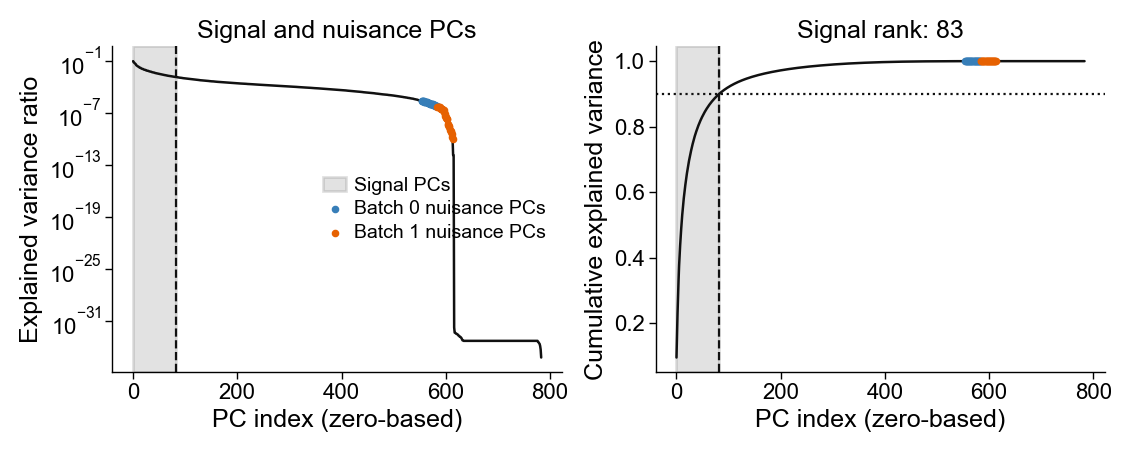

In [8]:
if RUN_EXPERIMENT:
    pca_components = experiment.pca.components_
    pca_mean = experiment.pca.mean_
    spectrum = experiment.pca.explained_variance_
    signal_rank = experiment.signal_rank
    nuisance0, nuisance1 = experiment.alpha_tail_indices, experiment.beta_tail_indices
else:
    with np.load(experiment.run_dir / "data/construction.npz", allow_pickle=False) as data:
        pca_components, pca_mean = data["pca_components"], data["pca_mean"]
        spectrum = data["pca_variance"]
    manifest = runs.configs["original"]
    signal_rank = int(manifest["signal_rank"])
    nuisance0 = np.asarray(manifest["alpha_tail_pca_indices"])
    nuisance1 = np.asarray(manifest["beta_tail_pca_indices"])
variance_ratio = spectrum / spectrum.sum()
cumulative = np.cumsum(variance_ratio)
pc_indices = np.arange(len(spectrum))
signal_color = registry.resolve("joint-pca").color
batch_colors = drawing.GALLERY_BATCH_COLOURS
fig, axes = plt.subplots(1, 2, figsize=layout.full_width(2.1), layout="constrained")
for ax, values in zip(axes, (variance_ratio, cumulative)):
    ax.plot(pc_indices, values, color=signal_color, linewidth=0.9)
    ax.axvspan(-0.5, signal_rank - 0.5, color=signal_color, alpha=0.12, label="Signal PCs")
    for batch, indices in enumerate((nuisance0, nuisance1)):
        ax.scatter(
            indices,
            values[indices],
            color=batch_colors[batch],
            s=12,
            label=f"Batch {batch} nuisance PCs",
            zorder=3,
        )
    ax.axvline(signal_rank - 1, color=signal_color, linestyle="--", linewidth=0.8)
    ax.set_xlabel("PC index (zero-based)")
axes[0].set(yscale="log", ylabel="Explained variance ratio", title="Signal and nuisance PCs")
axes[1].set(ylabel="Cumulative explained variance", title=f"Signal rank: {signal_rank}")
axes[1].axhline(
    config.data.signal_variance_target, color=signal_color, linestyle=":", linewidth=0.8
)
axes[0].legend(fontsize=drawing.PANEL_TITLE_PT)
plt.show()

## 5. Construct the class-dependent orthogonal batch effect
Draw Gaussian directions in each batch's nuisance basis, normalize, apply independently permuted
class scales, and center the ten vectors. Centering changes final norms; the audit retains both
assigned scales and resulting norms. Different seeded streams implement independence.
Orthogonality assertions protect the construction to numerical precision.

In [9]:
def make_class_corruptions(basis, seed, class_scales):
    rng = np.random.default_rng(seed)
    coefficients = rng.normal(size=(10, basis.shape[0]))
    directions = coefficients @ basis
    directions /= np.linalg.norm(directions, axis=1, keepdims=True)
    vectors = np.asarray(class_scales)[:, None] * directions
    return (vectors - vectors.mean(axis=0, keepdims=True), coefficients)

In [10]:
if RUN_EXPERIMENT:
    experiment.lead_basis = experiment.pca.components_[: experiment.signal_rank]
    experiment.alpha_tail_basis = experiment.pca.components_[experiment.alpha_tail_indices]
    experiment.beta_tail_basis = experiment.pca.components_[experiment.beta_tail_indices]
    experiment.alphas, experiment.betas = ({}, {})
    experiment.alpha_norms, experiment.beta_norms = ({}, {})
    audit_records = []
    for corruption_seed in experiment.config.corruption.corruption_seeds:
        scale_values = np.asarray(experiment.config.corruption.class_corruption_scales)
        alpha_scales = np.random.default_rng(
            corruption_seed + experiment.config.corruption.batch0_scale_seed_offset
        ).permutation(scale_values)
        beta_scales = np.random.default_rng(
            corruption_seed + experiment.config.corruption.batch1_scale_seed_offset
        ).permutation(scale_values)
        beta_seed = corruption_seed + experiment.config.corruption.batch1_seed_offset
        alpha, alpha_coefficients = make_class_corruptions(
            experiment.alpha_tail_basis, corruption_seed, alpha_scales
        )
        beta, beta_coefficients = make_class_corruptions(
            experiment.beta_tail_basis, beta_seed, beta_scales
        )
        alpha_norms = np.linalg.norm(alpha, axis=1)
        beta_norms = np.linalg.norm(beta, axis=1)
        assert np.linalg.norm(alpha.mean(axis=0)) < 1e-12
        assert np.linalg.norm(beta.mean(axis=0)) < 1e-12
        assert np.linalg.norm(alpha @ experiment.lead_basis.T, axis=1).max() < 1e-10
        assert np.linalg.norm(beta @ experiment.lead_basis.T, axis=1).max() < 1e-10
        assert np.max(np.abs(alpha @ beta.T)) < 1e-10
        experiment.alphas[corruption_seed], experiment.betas[corruption_seed] = (alpha, beta)
        experiment.alpha_norms[corruption_seed], experiment.beta_norms[corruption_seed] = (
            alpha_norms,
            beta_norms,
        )
        for batch, direction_seed, vectors, coefficients, norms, indices, scales in [
            (
                0,
                corruption_seed,
                alpha,
                alpha_coefficients,
                alpha_norms,
                experiment.alpha_tail_indices,
                alpha_scales,
            ),
            (
                1,
                beta_seed,
                beta,
                beta_coefficients,
                beta_norms,
                experiment.beta_tail_indices,
                beta_scales,
            ),
        ]:
            for digit in range(10):
                audit_records.append(
                    {
                        "corruption_seed": corruption_seed,
                        "batch": batch,
                        "direction_seed": direction_seed,
                        "class": digit,
                        "configured_scale": scales[digit],
                        "final_corruption_norm": norms[digit],
                        "leading_projection_norm": np.linalg.norm(
                            vectors[digit] @ experiment.lead_basis.T
                        ),
                        "tail_pca_indices": json.dumps(indices.tolist()),
                        "tail_pc_coefficients": json.dumps(coefficients[digit].tolist()),
                    }
                )
    experiment.audit = pd.DataFrame(audit_records)
    assert len(np.unique(experiment.tail_indices)) == len(experiment.tail_indices)
    assert not np.intersect1d(experiment.alpha_tail_indices, experiment.beta_tail_indices).size
    assert np.max(np.abs(experiment.alpha_tail_basis @ experiment.beta_tail_basis.T)) < 1e-10

In [11]:
if RUN_EXPERIMENT:
    # Persist config, clean arrays, PCA, and reference ε.
    experiment.initialize_run()
    audit = experiment.audit
else:
    audit = pd.read_csv(saved_synthetic.audit_path(runs.run_dirs["original"]))
for seed, draw in audit.groupby("corruption_seed"):
    scales = draw.pivot(index="class", columns="batch", values="configured_scale")
    np.testing.assert_array_equal(np.sort(scales[0]), np.sort(scales[1]))
assert audit.leading_projection_norm.max() < 1e-10
display(
    audit.groupby("batch")[["configured_scale", "final_corruption_norm", "leading_projection_norm"]]
    .agg(["min", "max"])
    .round(6)
)

if RUN_EXPERIMENT:
    reference_audit = source_audit
    if source_manifest["variant"] == "parallel_pc1":
        reference_audit = pd.concat([pd.read_csv(SOURCE_RUN_DIR / mode / "diagnostics/corruption_audit.csv")
                                    for mode in config.data.modes], ignore_index=True)
    if SMOKE:
        reference_audit = reference_audit.loc[reference_audit.corruption_seed.isin(config.corruption.corruption_seeds)]
    pd.testing.assert_frame_equal(experiment.audit.reset_index(drop=True),
        reference_audit.drop(columns="mode", errors="ignore").reset_index(drop=True)
        if "mode" not in experiment.audit else reference_audit.reset_index(drop=True),
        check_dtype=False, check_exact=False, atol=1e-12, rtol=1e-12)
    if not SMOKE and (not BUILD_FROM_MNIST or construction_match == "identical"):
        assert experiment.construction_sha256 == source_manifest["construction_sha256"], "Construction bytes changed"
    from importlib.metadata import version
    provenance = dict(reference_lambda=0.0, source_run=str(SOURCE_RUN_DIR),
        source_construction_sha256=hashlib.sha256(source_construction.read_bytes()).hexdigest(),
        implementation_revision=(subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True, capture_output=True).stdout.strip() or "unknown"),
        benchmark_settings=benchmark_settings, tsne_n_jobs=TSNE_N_JOBS, smoke=SMOKE,
        package_versions={name: version(name) for name in ("numpy", "scipy", "scikit-learn", "opentsne", "POT", "scanorama")},
        notes="Fresh method outputs; recorded construction and order; fixed epsilon at lambda=0")
    (experiment.run_dir / "ablation_manifest.json").write_text(json.dumps(provenance, indent=2, sort_keys=True))


configured_scale      final_corruption_norm            \
                   min  max                   min       max   
batch                                                         
0                 0.35  2.6              0.599485  2.437392   
1                 0.35  2.6              0.536259  2.414736   

      leading_projection_norm       
                          min  max  
batch                               
0                         0.0  0.0  
1                         0.0  0.0

### All digits: clean and corrupted batches
One example per digit, with the same observation shown clean and noisy within each batch.
Rows are batch 0 clean/noisy, then batch 1 clean/noisy; observations across batches are distinct.
Choose λ, representation, and corruption seed in `plot_config` above. Clipping to [0,1] is for
image display only; affinity and embedding calculations use the unclipped arrays.

Digit grid: original, λ=10, corruption seed 0


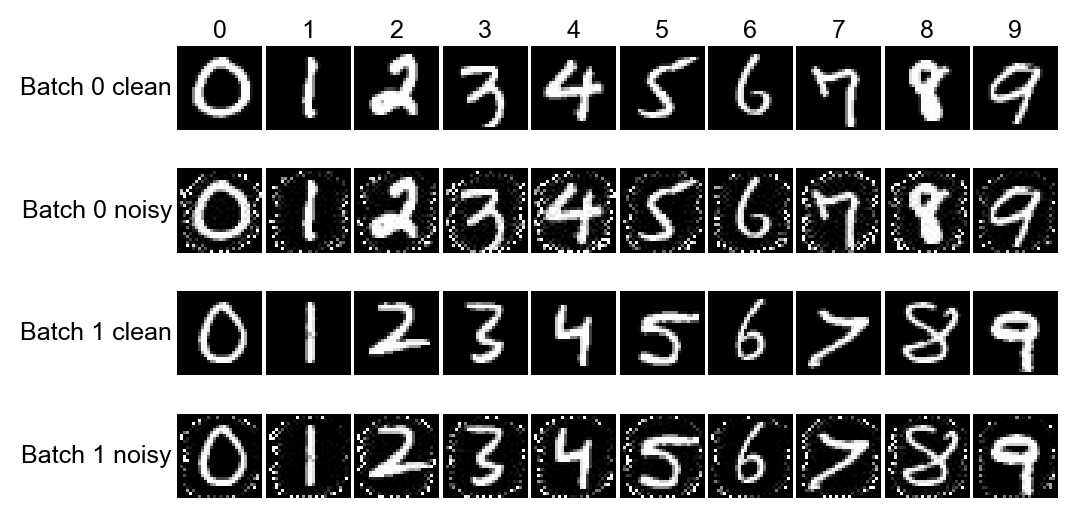

In [12]:
if RUN_EXPERIMENT:
    clean0, clean1 = experiment.x0_images, experiment.x1_images
else:
    with np.load(experiment.run_dir / "data/construction.npz", allow_pickle=False) as data:
        clean0, clean1 = data["clean0"], data["clean1"]
recorded_pca = SimpleNamespace(components_=pca_components)
alpha, beta = drawing.reconstruct_corruptions(
    "two_sided_independent_scales", audit, recorded_pca, plot_config.corruption_seed
)
if plot_config.mode == "original":
    display_clean = (clean0, clean1)
elif plot_config.mode == "projected":
    lead = pca_components[:signal_rank]
    display_clean = tuple((x - pca_mean) @ lead.T @ lead + pca_mean for x in (clean0, clean1))
else:
    raise ValueError("Diagnostic mode must be original or projected")
indices = [
    [np.flatnonzero(labels == digit)[0] for digit in range(10)] for labels in (labels0, labels1)
]
images = []
for batch, (clean, vectors) in enumerate(zip(display_clean, (alpha, beta))):
    examples = clean[indices[batch]]
    images.extend((examples, examples + plot_config.magnitude * vectors))
fig, axes = plt.subplots(4, 10, figsize=layout.full_width(2.8), layout="none")
row_labels = ("Batch 0 clean", "Batch 0 noisy", "Batch 1 clean", "Batch 1 noisy")
for row, (examples, label) in enumerate(zip(images, row_labels)):
    for digit, ax in enumerate(axes[row]):
        ax.imshow(np.clip(examples[digit], 0, 1).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.set_title(str(digit))
    axes[row, 0].set_ylabel(label, rotation=0, ha="right", va="center")
fig.subplots_adjust(left=0.19, right=0.99, top=0.9, bottom=0.04, wspace=0.05, hspace=0.08)
print(
    f"Digit grid: {plot_config.mode}, λ={plot_config.magnitude:g}, "
    f"corruption seed {plot_config.corruption_seed}"
)
plt.show()

## 6. Sanity checks / visual validation
For corruption strength λ, the cost decomposes into clean cost, λ² row/column norm offsets,
and clean–nuisance interactions; the cross-nuisance term vanishes. Signal projection removes
the interactions. Adding only row/column offsets leaves a balanced OT plan invariant at fixed ε.
Adaptive ε can change the plan. Both policies are tested, including λ=0.

In [13]:
if RUN_EXPERIMENT:
    (cost_records, experiment.reference_plans) = ([], {})
    for mode in experiment.config.data.modes:
        (base0, base1) = experiment.clean_by_mode[mode]
        clean_cost = experiment.squared_cost(base0, base1)
        for rel_reg in experiment.config.ot.rel_reg:
            for epsilon_policy in experiment.config.ot.epsilon_policies:
                experiment.reference_plans[mode, rel_reg, epsilon_policy] = experiment.compute_policy_plan(base0, base1, mode, rel_reg, epsilon_policy)
        for corruption_seed in experiment.config.corruption.corruption_seeds:
            (alpha, beta) = (experiment.alphas[corruption_seed], experiment.betas[corruption_seed])
            (alpha_i, beta_j) = (alpha[experiment.labels0], beta[experiment.labels1])
            (alpha_norms, beta_norms) = (experiment.alpha_norms[corruption_seed], experiment.beta_norms[corruption_seed])
            for magnitude in tuple(dict.fromkeys((0.0, *experiment.config.corruption.magnitudes))):
                (x0, x1) = experiment.make_batches(mode, magnitude, corruption_seed)
                observed_cost = experiment.squared_cost(x0, x1)
                row_offset = magnitude ** 2 * alpha_norms[experiment.labels0] ** 2
                column_offset = magnitude ** 2 * beta_norms[experiment.labels1] ** 2
                residual = observed_cost - clean_cost - row_offset[:, None] - column_offset[None, :]
                if mode == 'projected':
                    numerical_tolerance = 1e-09 * (1.0 + np.max(clean_cost) + np.max(row_offset) + np.max(column_offset))
                    if np.max(np.abs(residual)) > numerical_tolerance:
                        raise AssertionError('Projected row-plus-column cost identity failed')
                alpha_signal = np.sum(base0 * alpha_i, axis=1)[:, None] - alpha_i @ base1.T
                beta_signal = base0 @ beta_j.T - np.sum(base1 * beta_j, axis=1)[None, :]
                signal_interaction = 2 * magnitude * (alpha_signal - beta_signal)
                nuisance_cross = -2 * magnitude ** 2 * (alpha_i @ beta_j.T)
                analytic_residual = signal_interaction + nuisance_cross
                identity_error = residual - analytic_residual
                offset_matrix = row_offset[:, None] + column_offset[None, :]
                offset_rms = float(np.sqrt(np.mean(offset_matrix ** 2)))
                for rel_reg in experiment.config.ot.rel_reg:
                    for epsilon_policy in experiment.config.ot.epsilon_policies:
                        (plan, artifacts) = experiment.compute_policy_plan(x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=True)
                        reference = experiment.reference_plans[mode, rel_reg, epsilon_policy]
                        cost_records.append({'mode': mode, 'corruption_seed': corruption_seed, 'magnitude': magnitude, 'rel_reg': rel_reg, 'epsilon_policy': epsilon_policy, 'epsilon': float(artifacts['epsilon']), 'epsilon_over_reference': float(artifacts['epsilon']) / experiment.reference_epsilons[mode][float(rel_reg)], 'row_offset_rms': float(np.sqrt(np.mean(row_offset ** 2))), 'column_offset_rms': float(np.sqrt(np.mean(column_offset ** 2))), 'row_plus_column_offset_rms': offset_rms, 'signal_interaction_rms': float(np.sqrt(np.mean(signal_interaction ** 2))), 'signal_interaction_max_abs': float(np.max(np.abs(signal_interaction))), 'alpha_beta_cross_rms': float(np.sqrt(np.mean(nuisance_cross ** 2))), 'row_plus_column_residual_rms': float(np.sqrt(np.mean(residual ** 2))), 'row_plus_column_residual_max_abs': float(np.max(np.abs(residual))), 'interaction_to_offset_rms_ratio': float(np.sqrt(np.mean(signal_interaction ** 2))) / offset_rms if offset_rms else 0.0, 'decomposition_identity_error_max_abs': float(np.max(np.abs(identity_error))), 'relative_ot_plan_change': float(np.linalg.norm(plan - reference) / np.linalg.norm(reference)), **full_plan_record(plan, artifacts, reference, x0, x1, mode, rel_reg, epsilon_policy)})
    experiment.cost_diagnostics = pd.DataFrame(cost_records)
    experiment.verify_costs()
    experiment.save_stage('cost')
    cost = experiment.cost_diagnostics
else:
    cost = runs.cost

### Full plans: ε₀ reference and solver validity
Each policy is compared to its own λ=0 plan using ½Σ|Pλ−P₀|; the policies are also
compared at the same λ. Uniform marginals and total mass are checked without renormalizing.
Sinkhorn's stopping error and the declared plan-distance tolerance are different quantities.
Only constant parallel translation / signal-projected orthogonal inputs are exact invariance controls.
`sinkhorn_niter` retains POT's zero-based last-iteration index.


All λ-sweep plots show only λ > 0. The stored λ=0 plans calibrate ε₀ and remain the internal reference for TV/Jaccard; zero is not an experimental point in these plots.


In [14]:
assert cost.sinkhorn_converged.all(), "Inspect unconverged solves before interpreting plan differences."
assert np.isfinite(cost.tv_to_lambda0).all()
assert (cost.transported_mass - 1).abs().max() < PLAN_TV_ATOL
baseline = cost.loc[cost.magnitude == 0]
assert baseline.tv_to_lambda0.max() <= PLAN_TV_ATOL
assert baseline.fixed_vs_adaptive_tv.max() <= PLAN_TV_ATOL
invariant_mode = "constant" if "constant" in config.data.modes else "projected"
invariant = cost.loc[(cost["mode"] == invariant_mode) & (cost.epsilon_policy == "fixed_at_lambda_0")]
assert invariant.tv_to_lambda0.max() <= PLAN_TV_ATOL
print("Converged solves:", cost.sinkhorn_converged.sum(), "/", len(cost))
print("Maximum invariant-control TV:", invariant.tv_to_lambda0.max())
display(cost.groupby(["mode", "epsilon_policy", "rel_reg"])[
    ["tv_to_lambda0", "fixed_vs_adaptive_tv", "sinkhorn_niter", "sinkhorn_final_error",
     "row_marginal_max_error", "column_marginal_max_error"]].max())
adaptive = cost.loc[cost.epsilon_policy == "adaptive_per_magnitude"]
np.testing.assert_allclose(adaptive.epsilon,
    adaptive.rel_reg * adaptive.median_squared_distance, rtol=1e-12, atol=1e-12)
fixed = cost.loc[cost.epsilon_policy == "fixed_at_lambda_0"]
assert fixed.groupby(["mode", "rel_reg"]).epsilon.nunique().eq(1).all()


Converged solves: 120 / 120
Maximum invariant-control TV: 1.6145094631382634e-15


tv_to_lambda0  fixed_vs_adaptive_tv  \
mode      epsilon_policy         rel_reg                                        
original  adaptive_per_magnitude 1.0       6.760525e-02              0.067642   
                                 10.0      6.510671e-03              0.006515   
          fixed_at_lambda_0      1.0       1.694218e-03              0.067642   
                                 10.0      1.702182e-04              0.006515   
projected adaptive_per_magnitude 1.0       7.602537e-02              0.076025   
                                 10.0      7.295558e-03              0.007296   
          fixed_at_lambda_0      1.0       1.614509e-15              0.076025   
                                 10.0      4.595274e-16              0.007296   

                                          sinkhorn_niter  \
mode      epsilon_policy         rel_reg                   
original  adaptive_per_magnitude 1.0                  10   
                                 10.0                 10   
          fixed_at_lambda_0      1.0                  10   
                                 10.0                 10   
projected adaptive_per_magnitude 1.0                  10   
                                 10.0                 10   
          fixed_at_lambda_0      1.0                  10   
                                 10.0                 10   

                                          sinkhorn_final_error  \
mode      epsilon_policy         rel_reg                         
original  adaptive_per_magnitude 1.0              3.652780e-17   
                                 10.0             3.537491e-17   
          fixed_at_lambda_0      1.0              3.606011e-17   
                                 10.0             3.679074e-17   
projected adaptive_per_magnitude 1.0              3.649045e-17   
                                 10.0             3.575172e-17   
          fixed_at_lambda_0      1.0              3.687244e-17   
                                 10.0             3.675557e-17   

                                          row_marginal_max_error  \
mode      epsilon_policy         rel_reg                           
original  adaptive_per_magnitude 1.0                4.336809e-19   
                                 10.0               4.336809e-19   
          fixed_at_lambda_0      1.0                4.336809e-19   
                                 10.0               4.336809e-19   
projected adaptive_per_magnitude 1.0                4.336809e-19   
                                 10.0               4.336809e-19   
          fixed_at_lambda_0      1.0                4.336809e-19   
                                 10.0               4.336809e-19   

                                          column_marginal_max_error  
mode      epsilon_policy         rel_reg                             
original  adaptive_per_magnitude 1.0                   4.987330e-18  
                                 10.0                  4.770490e-18  
          fixed_at_lambda_0      1.0                   4.553649e-18  
                                 10.0                  4.987330e-18  
projected adaptive_per_magnitude 1.0                   4.336809e-18  
                                 10.0                  4.336809e-18  
          fixed_at_lambda_0      1.0                   4.770490e-18  
                                 10.0                  4.336809e-18

In [15]:
def rounded_diagnostic_ylim(ax, *, probability=False):
    """Fit data AND error bars; bounds are multiples of 5 at a suitable decimal scale."""
    siblings = ax.get_shared_y_axes().get_siblings(ax)
    intervals = np.array([other.dataLim.intervaly for other in siblings])
    lo, hi = intervals[:, 0].min(), intervals[:, 1].max()
    if not np.isfinite([lo, hi]).all():
        return
    span = hi - lo
    if span <= max(abs(lo), abs(hi), 1.0) * 1e-12:
        span = .05 if probability else max(abs(lo) * .1, 1e-6)
    quantum = 5 * 10.0 ** (np.floor(np.log10(span)) - 1)
    lower = np.floor((lo - .05 * span) / quantum) * quantum
    upper = np.ceil((hi + .05 * span) / quantum) * quantum
    if probability:
        # Keep mean ± SD visible even if a bounded score's error bar crosses 0 or 1.
        lower = max(0.0, lower) if lo >= 0 else lower
        upper = min(1.0, upper) if hi <= 1 else upper
    if upper <= lower:
        lower, upper = (max(0.0, hi - .05), min(1.0, hi + .05)) if probability else (lo - quantum, hi + quantum)
    ax.set_ylim(float(lower), float(upper))

# Zero is retained in the saved tables for calibration and reference comparisons only.
DISPLAY_MAGNITUDES = tuple(float(x) for x in config.corruption.magnitudes if x > 0)
assert DISPLAY_MAGNITUDES

def sweep_only(frame):
    return frame.loc[frame.magnitude.isin(DISPLAY_MAGNITUDES)].copy()

def policy_panel(ax, frame, metric, ylabel, title, *, bounded=False):
    """Mean ± sample SD over corruption seeds; no lambda-zero observation is plotted."""
    for policy, group in sweep_only(frame).groupby("epsilon_policy", sort=False):
        fixed = policy == "fixed_at_lambda_0"
        if metric == "fixed_vs_adaptive_tv" and fixed:
            continue  # This is one paired comparison, not one curve per policy.
        table = group.groupby("magnitude")[metric].agg(["mean", "std"]).reset_index()
        color = registry.resolve("ot").color
        ax.errorbar(table.magnitude, table["mean"], yerr=table["std"].fillna(0),
            color=color, marker="o" if fixed else "s", markersize=3, capsize=1.5,
            markerfacecolor="white" if fixed else color,
            linestyle=(0, (4, 2.5)) if fixed else "-", linewidth=1.1,
            label=r"Fixed $\epsilon_0$" if fixed else r"Adaptive $\epsilon_\lambda$")
    ax.set(xlabel=r"$\lambda$", ylabel=ylabel, title=title, xticks=DISPLAY_MAGNITUDES)
    if bounded:
        ax.set_ylim(-.03, 1.05)

def ablation_curves(frame, metrics, *, policy_column="epsilon_policy", bounded=False):
    assert policy_column == "epsilon_policy"
    modes = list(config.data.modes)
    fig, axes = plt.subplots(len(modes), len(metrics), squeeze=False,
        figsize=layout.full_width(1.9 * len(modes)), layout="constrained")
    for row, mode in enumerate(modes):
        for ax, (metric, ylabel) in zip(axes[row], metrics):
            policy_panel(ax, frame.loc[frame["mode"] == mode], metric, ylabel,
                mode.replace("projected", "Signal-projected"), bounded=bounded)
        for ax in axes[row]:
            rounded_diagnostic_ylim(ax, probability=bounded)
        axes[row, 0].legend(fontsize=drawing.PANEL_TITLE_PT, handlelength=4)
    return fig


Full-plan comparisons · rel_reg=1 · λ=0 reference


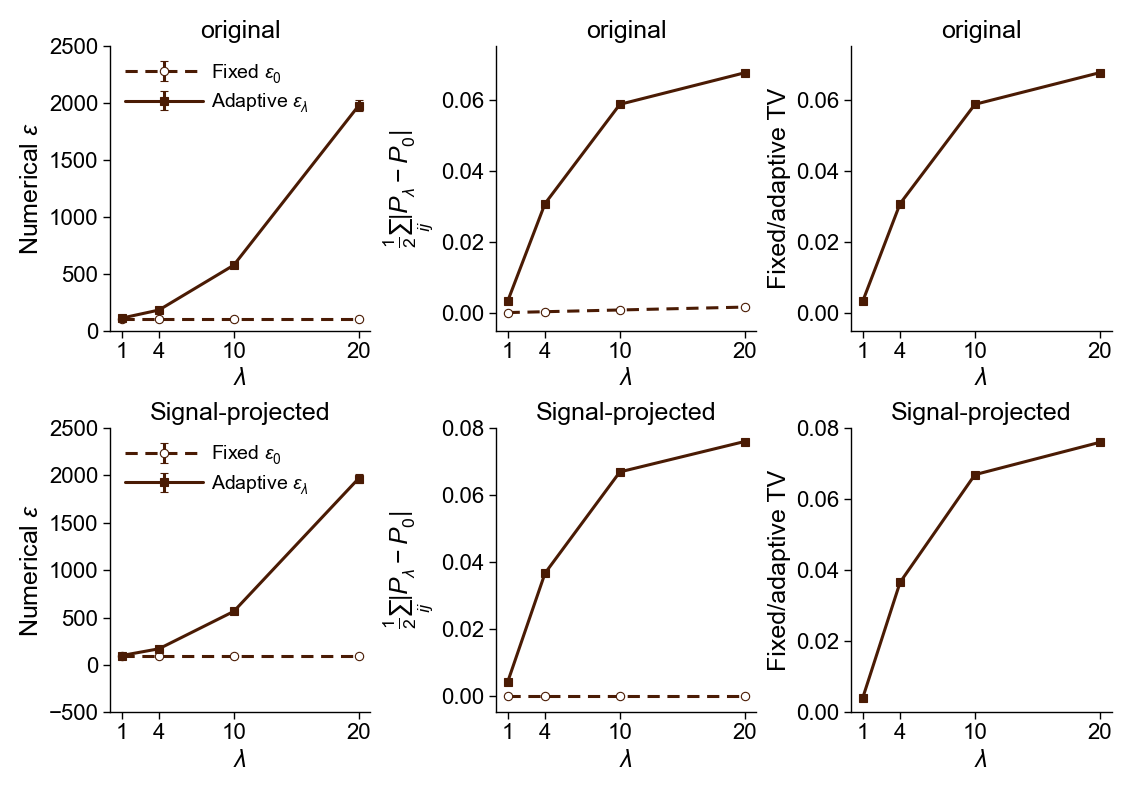

Full-plan comparisons · rel_reg=10 · λ=0 reference


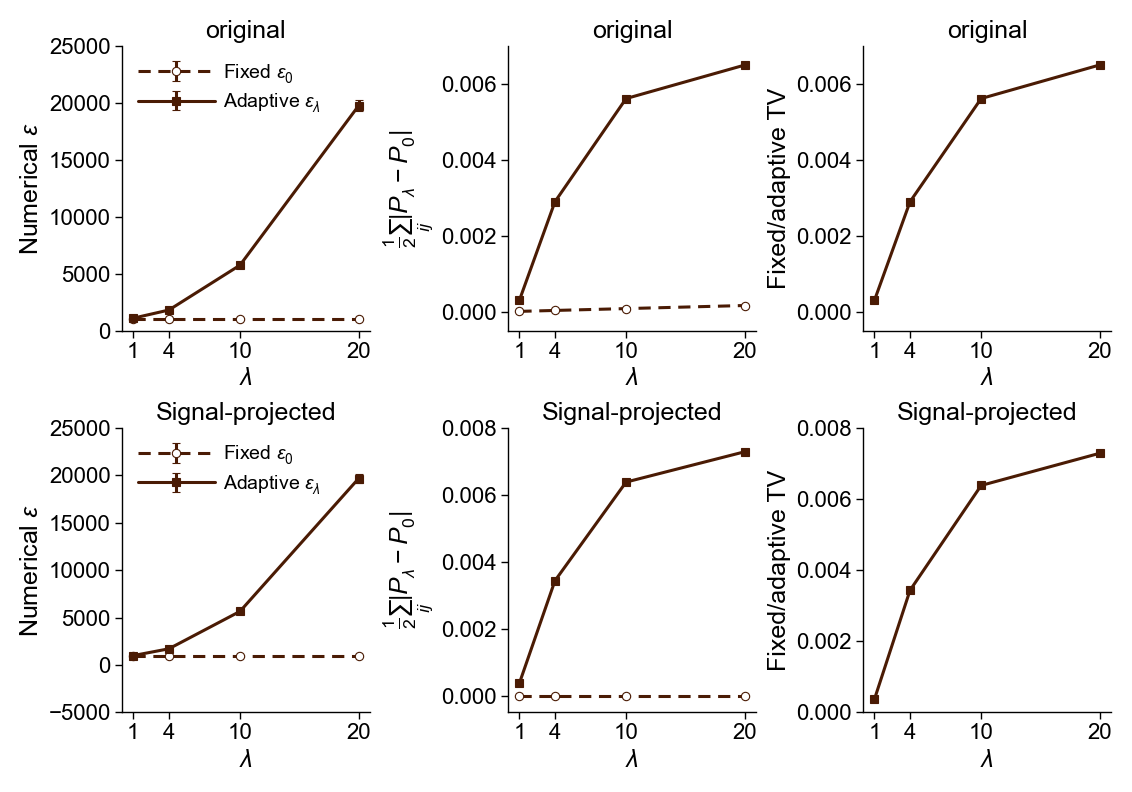

In [16]:
for rel_reg in config.ot.rel_reg:
    selected = cost.loc[np.isclose(cost.rel_reg, rel_reg)]
    print(f"Full-plan comparisons · rel_reg={rel_reg:g} · λ=0 reference")
    ablation_curves(selected, [("epsilon", r"Numerical $\epsilon$"),
        ("tv_to_lambda0", r"$\frac{1}{2}\sum_{ij}|P_\lambda-P_0|$"),
        ("fixed_vs_adaptive_tv", "Fixed/adaptive TV")])
    plt.show()

In [17]:
control = cost.query("mode == 'projected' and epsilon_policy == 'fixed_at_lambda_0'")
assert cost.decomposition_identity_error_max_abs.max() < 1e-8
assert len(control) and control.relative_ot_plan_change.max() < 1e-7
print("Maximum decomposition error:", cost.decomposition_identity_error_max_abs.max())
print("Projected fixed-ε relative plan change:", control.relative_ot_plan_change.max())
display(
    cost.groupby(["mode", "epsilon_policy"])[
        ["relative_ot_plan_change", "row_plus_column_residual_max_abs"]
    ]
    .max()
    .round(6)
)

Maximum decomposition error: 3.0358300273210357e-12
Projected fixed-ε relative plan change: 4.291119184363342e-15


relative_ot_plan_change  \
mode      epsilon_policy                                    
original  adaptive_per_magnitude                 0.186872   
          fixed_at_lambda_0                      0.005680   
projected adaptive_per_magnitude                 0.210652   
          fixed_at_lambda_0                      0.000000   

                                  row_plus_column_residual_max_abs  
mode      epsilon_policy                                            
original  adaptive_per_magnitude                         15.092137  
          fixed_at_lambda_0                              15.092137  
projected adaptive_per_magnitude                          0.000000  
          fixed_at_lambda_0                               0.000000

### Paper panel A: existing strip layout
This calls the same strip construction function as the final paper figure (four representative
digits at λ=10). The previous notebook preview selected the alternate column layout;
the images themselves were not transposed. The paper drawing code is unchanged.

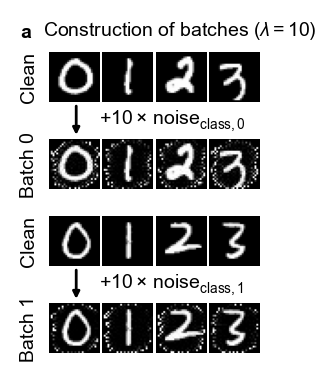

In [18]:
paper_seed = int(config.corruption.corruption_seeds[0])
paper_alpha, paper_beta = drawing.reconstruct_corruptions(
    "two_sided_independent_scales", audit, recorded_pca, paper_seed
)
with plt.rc_context({"figure.constrained_layout.use": False}):
    fig = plt.figure(figsize=layout.full_width(2.0))
    grid = fig.add_gridspec(1, 1)
    drawing.construction_panel_strip(
        fig,
        grid[0],
        clean0,
        labels0,
        clean1,
        labels1,
        paper_alpha,
        paper_beta,
        variant="two_sided_independent_scales",
        centred=True,
        inline=True,
    )
    drawing.lay_out_panels(fig)
    plt.show()

## 7. Cross-batch affinity experiment: EOT, shared kNN, mutual kNN
Extract top-k row and column supports from rectangular EOT plans. Shared supports are unions;
mutual supports are intersections. The existing graph utilities evaluate edge purity and the
fraction of query observations with a nonempty support. Coverage matters: high mutual purity
can coexist with isolated observations. The same diagnostics are measured for cross-batch kNN.

The fraction table averages corruption seeds separately for each representation and λ.
`within_batch_knn_edge_preservation` measures the fraction of each observation’s clean
within-batch kNN neighbors retained after corruption, averaged over observations and then
equally across batches. It excludes the observation itself. A value of 1 means all k neighbors
are retained; 0 means none. This measures neighborhood stability, not digit purity or batch mixing.

In [19]:
def cross_supports(plan):
    k = config.competitors.cross_batch_k
    row = experiment.rectangular_topk_support(plan, k, axis=1)
    column = experiment.rectangular_topk_support(plan, k, axis=0)
    # The current OT-tSNE implementation selects the cross scores directly from P.
    # cross_split uses exactly its proportional quotas/symmetrization, without computing diagonals.
    selection = select_four_block(BlockScores.from_plan(plan, None),
        effective_k=config.ot.ot_effective_k, rule="cross_split", graph_symmetrization="or")
    graph = graph_from_pairs(selection.rows, selection.cols, sum(plan.shape))
    embedded_cross = graph[:plan.shape[0], plan.shape[0]:].toarray() > 0
    return dict(row_top_k=row, column_top_k=column, shared_or=row | column,
                mutual_and=row & column, ot_tsne_cross=embedded_cross)

def edge_overlap_record(plan, reference):
    selected, baseline = cross_supports(plan), cross_supports(reference)
    values = {}
    for graph in selected:
        union = np.count_nonzero(selected[graph] | baseline[graph])
        intersection = np.count_nonzero(selected[graph] & baseline[graph])
        # Two empty supports are identical; the edge count exposes that degenerate case.
        values[f"{graph}_jaccard_to_lambda0"] = float(intersection / union) if union else 1.0
        values[f"{graph}_n_edges"] = int(np.count_nonzero(selected[graph]))
    return values

### Saved inputs for graph diagnostics
The helpers below restore the recorded observations, PCA basis, and seeded corruption vectors.
Cached-plan lookup checks the exact arrays and settings; load-only mode refuses an absent plan.
No OT solve or embedding fit is needed to re-evaluate graph metrics.


In [20]:
# Restore recorded inputs only when cached-plan diagnostics need them.
from ne_aligned_utils.evaluation.hubness import restore_saved_construction

def prepare_cached_plan_inputs(rel_reg=1.0):
    if not RUN_EXPERIMENT:
        restore_saved_construction(experiment)
        if "original" in config.data.modes:
            # Reuse the notebook's exact seeded reconstruction, avoiding CSV float-roundtrip drift.
            with np.load(experiment.run_dir / "data/construction.npz", allow_pickle=False) as data:
                components = data["pca_components"]
            manifest = runs.configs["original"]
            alpha_basis = components[manifest["alpha_tail_pca_indices"]]
            beta_basis = components[manifest["beta_tail_pca_indices"]]
            scales = np.asarray(config.corruption.class_corruption_scales)
            for seed in config.corruption.corruption_seeds:
                scale0 = np.random.default_rng(seed + config.corruption.batch0_scale_seed_offset).permutation(scales)
                scale1 = np.random.default_rng(seed + config.corruption.batch1_scale_seed_offset).permutation(scales)
                experiment.alphas[seed] = make_class_corruptions(alpha_basis, seed, scale0)[0]
                experiment.betas[seed] = make_class_corruptions(
                    beta_basis, seed + config.corruption.batch1_seed_offset, scale1)[0]
        # Read the exact numerical epsilon from the cached lambda-zero solver JSON, not a CSV.
        for mode in config.data.modes:
            zero0, zero1 = experiment.make_batches(mode, 0.0, config.corruption.corruption_seeds[0])
            _, zero_info = experiment.compute_policy_plan(zero0, zero1, mode, rel_reg,
                "adaptive_per_magnitude", return_artifacts=True)
            experiment.reference_epsilons[mode][float(rel_reg)] = zero_info["epsilon"]


In [21]:
if RUN_EXPERIMENT:
    DIAGNOSTIC_MAGNITUDES = tuple(dict.fromkeys((0.0, *experiment.config.corruption.magnitudes)))
    (affinity_records, knn_records) = ([], [])
    for mode in experiment.config.data.modes:
        (base0, base1) = experiment.clean_by_mode[mode]
        same_digit = experiment.labels0[:, None] == experiment.labels1[None, :]
        for corruption_seed in experiment.config.corruption.corruption_seeds:
            for magnitude in DIAGNOSTIC_MAGNITUDES:
                (x0, x1) = experiment.make_batches(mode, magnitude, corruption_seed)
                for rel_reg in experiment.config.ot.rel_reg:
                    for epsilon_policy in experiment.config.ot.epsilon_policies:
                        (plan, artifacts) = experiment.compute_policy_plan(x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=True)
                        reference = experiment.reference_plans[mode, rel_reg, epsilon_policy]
                        row_support = experiment.rectangular_topk_support(plan, experiment.config.competitors.cross_batch_k, axis=1)
                        column_support = experiment.rectangular_topk_support(plan, experiment.config.competitors.cross_batch_k, axis=0)
                        shared_support = row_support | column_support
                        mutual_support = row_support & column_support
                        (row_purity, row_coverage, row_degree) = experiment.support_stats(row_support, experiment.labels0, experiment.labels1)
                        (column_purity, column_coverage, column_degree) = experiment.support_stats(column_support.T, experiment.labels1, experiment.labels0)
                        (shared_purity, shared_coverage, shared_degree) = experiment.support_stats(shared_support, experiment.labels0, experiment.labels1)
                        (mutual_purity, mutual_coverage, mutual_degree) = experiment.support_stats(mutual_support, experiment.labels0, experiment.labels1)
                        affinity_records.append({'mode': mode, 'corruption_seed': corruption_seed, 'magnitude': magnitude, 'rel_reg': rel_reg, 'epsilon_policy': epsilon_policy, 'epsilon': float(artifacts['epsilon']), 'raw_same_digit_mass_fraction': float(plan[same_digit].sum() / plan.sum()), 'relative_ot_plan_change': float(np.linalg.norm(plan - reference) / np.linalg.norm(reference)), 'top_k': experiment.config.competitors.cross_batch_k, 'eot_row_digit_purity': row_purity, 'eot_row_nonempty_row_fraction': row_coverage, 'eot_row_mean_degree': row_degree, 'eot_column_digit_purity': column_purity, 'eot_column_nonempty_row_fraction': column_coverage, 'eot_column_mean_degree': column_degree, 'eot_shared_or_digit_purity': shared_purity, 'eot_shared_or_nonempty_row_fraction': shared_coverage, 'eot_shared_or_mean_degree': shared_degree, 'eot_mutual_and_digit_purity': mutual_purity, 'eot_mutual_and_nonempty_row_fraction': mutual_coverage, 'eot_mutual_and_mean_degree': mutual_degree, **edge_overlap_record(plan, reference)})
                diagnostics = experiment.knn_diagnostics(base0, base1, x0, x1, experiment.config.competitors.cross_batch_k)
                knn_records.append({'mode': mode, 'corruption_seed': corruption_seed, 'magnitude': magnitude, 'k': experiment.config.competitors.cross_batch_k, **diagnostics})
    experiment.affinity_diagnostics = pd.DataFrame(affinity_records)
    experiment.knn_diagnostics_table = pd.DataFrame(knn_records)
    experiment.save_stage('affinity')
    (affinity, knn) = (experiment.affinity_diagnostics, experiment.knn_diagnostics_table)
else:
    (affinity, knn) = (runs.affinity, runs.knn)

### Symmetric cross-batch graph purity
Re-evaluate the saved plans using the same row/column top-15 union graph. For its rectangular
support $A$, calculate the unweighted same-digit neighbor fraction at every batch-0 node using
rows of $A$, and at every batch-1 node using rows of $A^\top$. Average within each batch,
then give the two batches equal weight:
$Q_{\rm sym}=\frac12(Q_{0\to1}+Q_{1\to0})$.
The union graph covers every node, so neither batch has undefined node scores. This changes
only how graph purity is aggregated: the plans, selected edges, embedding metrics, and Jaccard
comparisons are unchanged. Appendix purity panels below use this symmetric score. The original
one-sided experiment artifacts remain intact; the main graph panels now also use symmetric scores, while embedding metrics are unchanged; both directional scores
and the new symmetric score are saved separately for audit.


In [22]:
# Re-score graph purity only: all plans come from this run's exact-input cache in load mode.
GRAPH_PURITY_K = config.competitors.cross_batch_k
purity_records = []
for rel_reg in config.ot.rel_reg:
    prepare_cached_plan_inputs(rel_reg)
    for mode in config.data.modes:
        for seed in config.corruption.corruption_seeds:
            for magnitude in config.corruption.magnitudes:
                x0, x1 = experiment.make_batches(mode, magnitude, seed)
                for policy in config.ot.epsilon_policies:
                    plan = experiment.compute_policy_plan(x0, x1, mode, rel_reg, policy)
                    rows = experiment.rectangular_topk_support(plan, GRAPH_PURITY_K, axis=1)
                    columns = experiment.rectangular_topk_support(plan, GRAPH_PURITY_K, axis=0)
                    support = rows | columns
                    q01, coverage0, _ = experiment.support_stats(support, experiment.labels0, experiment.labels1)
                    q10, coverage1, _ = experiment.support_stats(support.T, experiment.labels1, experiment.labels0)
                    assert coverage0 == coverage1 == 1.0
                    purity_records.append(dict(mode=mode, magnitude=magnitude, corruption_seed=seed,
                        rel_reg=float(rel_reg), epsilon_policy=policy,
                        graph_purity_batch0=q01, graph_purity_batch1=q10,
                        eot_shared_or_symmetric_digit_purity=.5 * (q01 + q10)))
symmetric_graph_purity = pd.DataFrame(purity_records)
purity_keys = ["mode", "magnitude", "corruption_seed", "rel_reg", "epsilon_policy"]
purity_columns = ["graph_purity_batch0", "graph_purity_batch1", "eot_shared_or_symmetric_digit_purity"]
assert symmetric_graph_purity[purity_columns].ge(0).all().all()
assert symmetric_graph_purity[purity_columns].le(1).all().all()
# Confirm that the old, batch-0 calculation has been reproduced before changing the plotted score.
purity_check = symmetric_graph_purity.merge(
    affinity[purity_keys + ["eot_shared_or_digit_purity"]], on=purity_keys, validate="one_to_one")
assert len(purity_check) == len(affinity)
assert np.allclose(purity_check.graph_purity_batch0, purity_check.eot_shared_or_digit_purity,
                   atol=1e-12, rtol=1e-10)
affinity = affinity.drop(columns=purity_columns, errors="ignore").merge(
    symmetric_graph_purity, on=purity_keys, validate="one_to_one")
symmetric_purity_summary = symmetric_graph_purity.groupby(
    ["mode", "magnitude", "rel_reg", "epsilon_policy"]
)[purity_columns].agg(["mean", "std"]).reset_index()
purity_dir = experiment.run_dir / "ablation/symmetric_graph_purity"
purity_dir.mkdir(parents=True, exist_ok=True)
symmetric_graph_purity.to_csv(purity_dir / "cross_batch_graph_purity_raw.csv", index=False)
symmetric_purity_summary.to_csv(purity_dir / "cross_batch_graph_purity_summary.csv", index=False)
(purity_dir / "config.json").write_text(json.dumps(dict(schema_version=1,
    run_dir=str(experiment.run_dir), graph="union_of_row_and_column_top_k", k=GRAPH_PURITY_K,
    aggregation="equal_batch_average_of_unweighted_node_purity", rel_reg=list(config.ot.rel_reg),
    epsilon_policies=list(config.ot.epsilon_policies), magnitudes=list(config.corruption.magnitudes),
    corruption_seeds=list(config.corruption.corruption_seeds),
    construction_sha256=json.loads((experiment.run_dir / "config.json").read_text())["construction_sha256"]), indent=2))
print(f"Re-scored {len(symmetric_graph_purity)} cached plans; directional and symmetric purity: {purity_dir}")
display(symmetric_purity_summary.loc[(symmetric_purity_summary.magnitude == max(DISPLAY_MAGNITUDES)) &
    np.isclose(symmetric_purity_summary.rel_reg, 1.0)].round(4))


# Re-score the shared and mutual kNN graphs with the identical two-batch averaging rule.
knn_purity_records = []
prepare_cached_plan_inputs(1.0)
for mode in config.data.modes:
    for seed in config.corruption.corruption_seeds:
        for magnitude in config.corruption.magnitudes:
            x0, x1 = experiment.make_batches(mode, magnitude, seed)
            forward = experiment.directed_knn(x0, x1, GRAPH_PURITY_K)
            backward = experiment.directed_knn(x1, x0, GRAPH_PURITY_K)
            support01 = np.zeros((len(x0), len(x1)), dtype=bool)
            support10 = np.zeros_like(support01)
            support01[np.arange(len(x0))[:, None], forward] = True
            support10[backward, np.arange(len(x1))[:, None]] = True
            record = dict(mode=mode, magnitude=magnitude, corruption_seed=seed, k=GRAPH_PURITY_K)
            for graph, support in (("shared", support01 | support10), ("mutual", support01 & support10)):
                q01, cov0, _ = experiment.support_stats(support, experiment.labels0, experiment.labels1)
                q10, cov1, _ = experiment.support_stats(support.T, experiment.labels1, experiment.labels0)
                record.update({f"{graph}_purity_batch0": q01, f"{graph}_purity_batch1": q10,
                    f"{graph}_symmetric_correct_class_neighbor_fraction": .5 * (q01 + q10),
                    f"{graph}_coverage_batch0": cov0, f"{graph}_coverage_batch1": cov1})
            knn_purity_records.append(record)
symmetric_knn_purity = pd.DataFrame(knn_purity_records)
knn_keys = ["mode", "magnitude", "corruption_seed", "k"]
for graph in ("shared", "mutual"):
    check = symmetric_knn_purity.merge(knn[knn_keys + [f"{graph}_correct_class_neighbor_fraction"]],
                                       on=knn_keys, validate="one_to_one")
    assert len(check) == len(knn)
    assert np.allclose(check[f"{graph}_purity_batch0"],
        check[f"{graph}_correct_class_neighbor_fraction"], atol=1e-12, equal_nan=True)
knn_new_columns = list(symmetric_knn_purity.columns.difference(knn_keys))
knn = knn.drop(columns=knn_new_columns, errors="ignore").merge(
    symmetric_knn_purity, on=knn_keys, validate="one_to_one")
symmetric_knn_purity.to_csv(purity_dir / "cross_batch_knn_purity_raw.csv", index=False)
print("Saved symmetric shared/mutual kNN purity; isolated nodes are excluded separately within each batch.")


Re-scored 120 cached plans; directional and symmetric purity: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__c70fb5e4/ablation/symmetric_graph_purity


mode magnitude rel_reg          epsilon_policy graph_purity_batch0  \
                                                                       mean   
16   original      20.0     1.0  adaptive_per_magnitude              0.6805   
17   original      20.0     1.0       fixed_at_lambda_0              0.6854   
36  projected      20.0     1.0  adaptive_per_magnitude              0.6821   
37  projected      20.0     1.0       fixed_at_lambda_0              0.6876   

           graph_purity_batch1         eot_shared_or_symmetric_digit_purity  \
       std                mean     std                                 mean   
16  0.0012              0.6794  0.0007                               0.6800   
17  0.0008              0.6849  0.0009                               0.6851   
36  0.0000              0.6802  0.0000                               0.6812   
37  0.0000              0.6865  0.0000                               0.6871   

            
       std  
16  0.0009  
17  0.0008  
36  0.0000  
37  0.0000

Saved symmetric shared/mutual kNN purity; isolated nodes are excluded separately within each batch.


### Paper panel B: sparse OT versus shared and mutual kNN
Reuse the manuscript's symmetrized-affinity panel immediately after the affinity experiment.
The companion coverage diagnostic shows how many observations retain a mutual match.
These plots use the already computed/saved tables; no embedding results are needed.

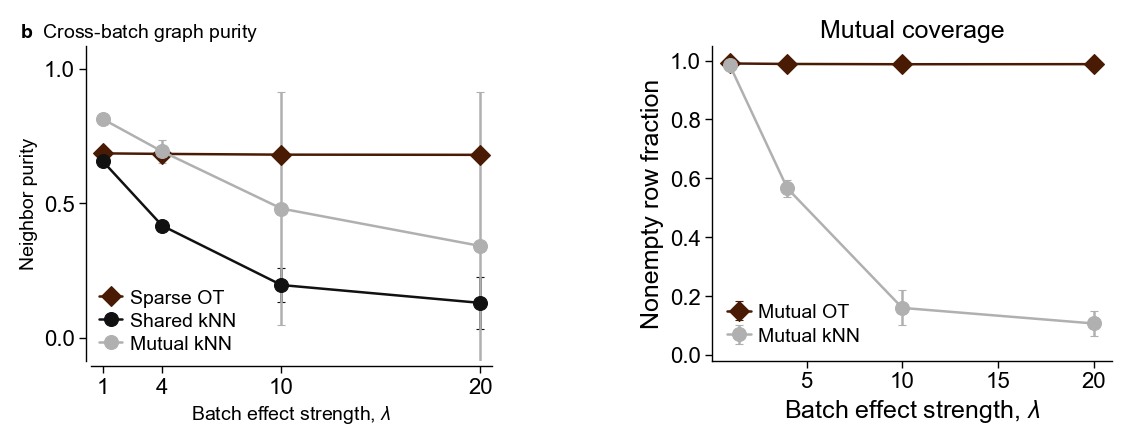

In [23]:
affinity_view = SimpleNamespace(
    configs={"original": {"magnitudes": DISPLAY_MAGNITUDES}}, knn=sweep_only(knn)
)
directed = sweep_only(affinity).loc[
    (affinity["mode"] == "original")
    & (affinity.epsilon_policy == "adaptive_per_magnitude")
    & np.isclose(affinity.rel_reg, plot_config.rel_reg)
]
with plt.rc_context({"figure.constrained_layout.use": False}):
    fig = plt.figure(figsize=layout.full_width(2.2))
    grid = fig.add_gridspec(1, 2, wspace=0.55)
    drawing.mechanism_panels(
        fig,
        (grid[0],),
        "two_sided_independent_scales",
        affinity_view,
        directed,
        letters=("B",),
        directed_panel=False,
    )
    ax = fig.add_subplot(grid[1])
    original_knn = sweep_only(knn).query("mode == 'original'")
    for frame, field, label, color, marker in (
        (
            directed,
            "eot_mutual_and_nonempty_row_fraction",
            "Mutual OT",
            registry.resolve("ot").color,
            registry.resolve("ot").marker,
        ),
        (
            original_knn,
            "mutual_nonempty_row_fraction",
            "Mutual kNN",
            registry.resolve("joint").color,
            "o",
        ),
    ):
        drawing.add_curve(ax, frame, field, label=label, color=color, marker=marker)
    ax.set(
        xlabel=r"Batch effect strength, $\lambda$",
        ylabel="Nonempty row fraction",
        title="Mutual coverage",
        ylim=(-0.02, 1.05),
    )
    ax.legend(fontsize=drawing.PANEL_TITLE_PT)
    drawing.lay_out_panels(fig)
    plt.show()

### Edge stability against zero
Compare each policy's graph at λ with its own λ=0 reference using
$J=|E_\lambda\cap E_0|/|E_\lambda\cup E_0|$. Sparse OT uses the row/column top-15 union;
the OT-tSNE cross-affinity support follows the method's split neighbor budget. Jaccard measures
edge membership, not weight agreement or digit correctness. Zero remains an internal reference;
only positive λ values are plotted. Full directed/union/intersection diagnostics remain saved.


shared_or_jaccard_to_lambda0  \
mode      epsilon_policy         rel_reg                                 
original  adaptive_per_magnitude 1.0                             0.929   
                                 10.0                            0.963   
          fixed_at_lambda_0      1.0                             0.964   
                                 10.0                            0.965   
projected adaptive_per_magnitude 1.0                             0.937   
                                 10.0                            0.993   
          fixed_at_lambda_0      1.0                             1.000   
                                 10.0                            1.000   

                                          ot_tsne_cross_jaccard_to_lambda0  
mode      epsilon_policy         rel_reg                                    
original  adaptive_per_magnitude 1.0                                 0.926  
                                 10.0                                0.961  
          fixed_at_lambda_0      1.0                                 0.962  
                                 10.0                                0.962  
projected adaptive_per_magnitude 1.0                                 0.930  
                                 10.0                                0.992  
          fixed_at_lambda_0      1.0                                 1.000  
                                 10.0                                1.000

Cross-batch supports · rel_reg=1


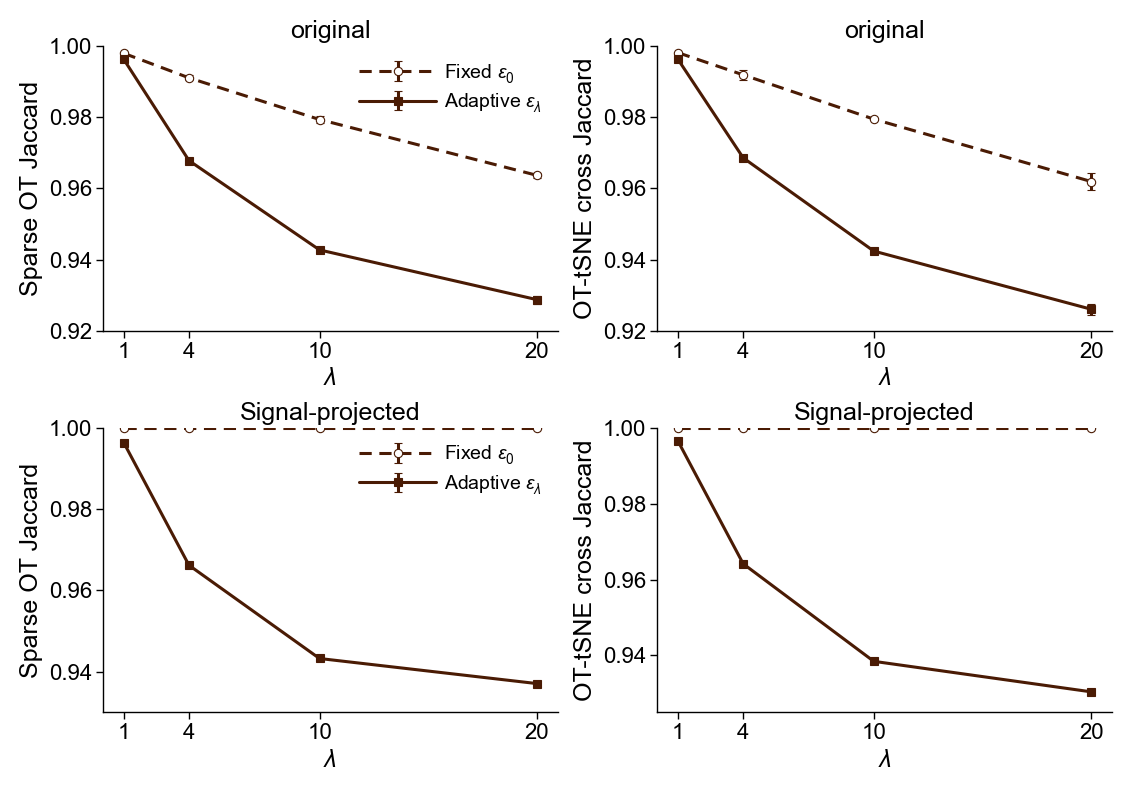

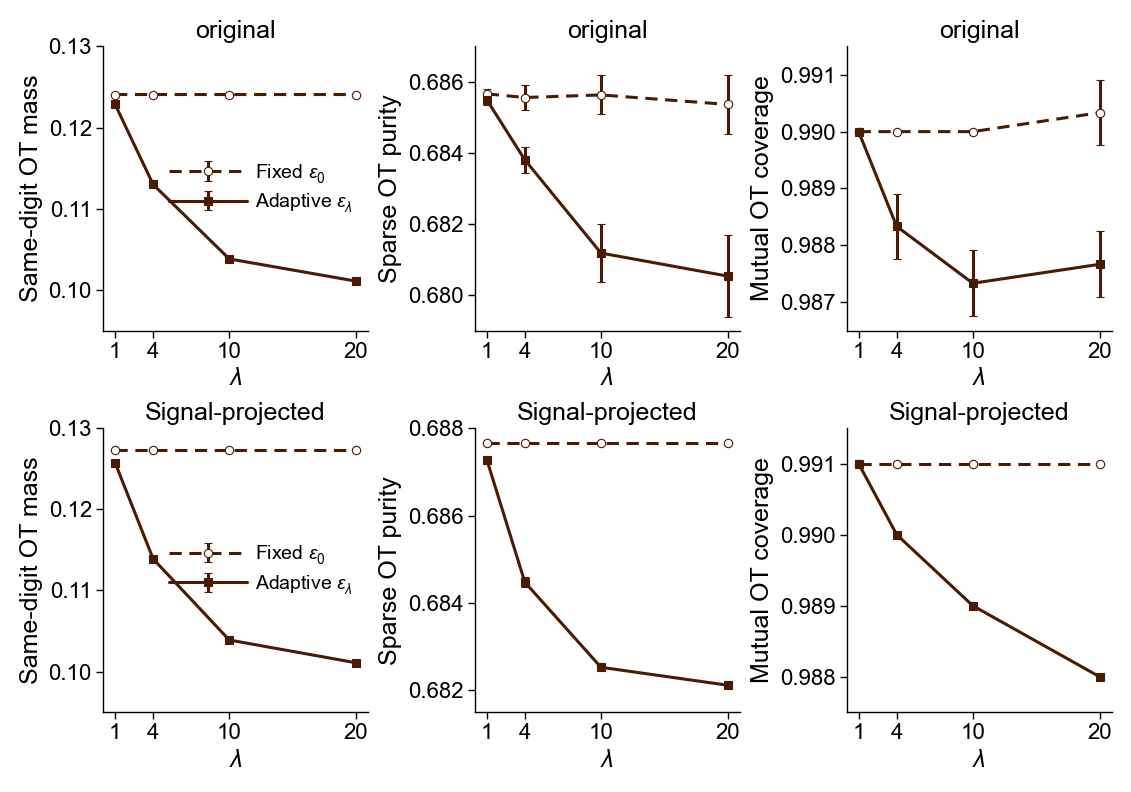

Cross-batch supports · rel_reg=10


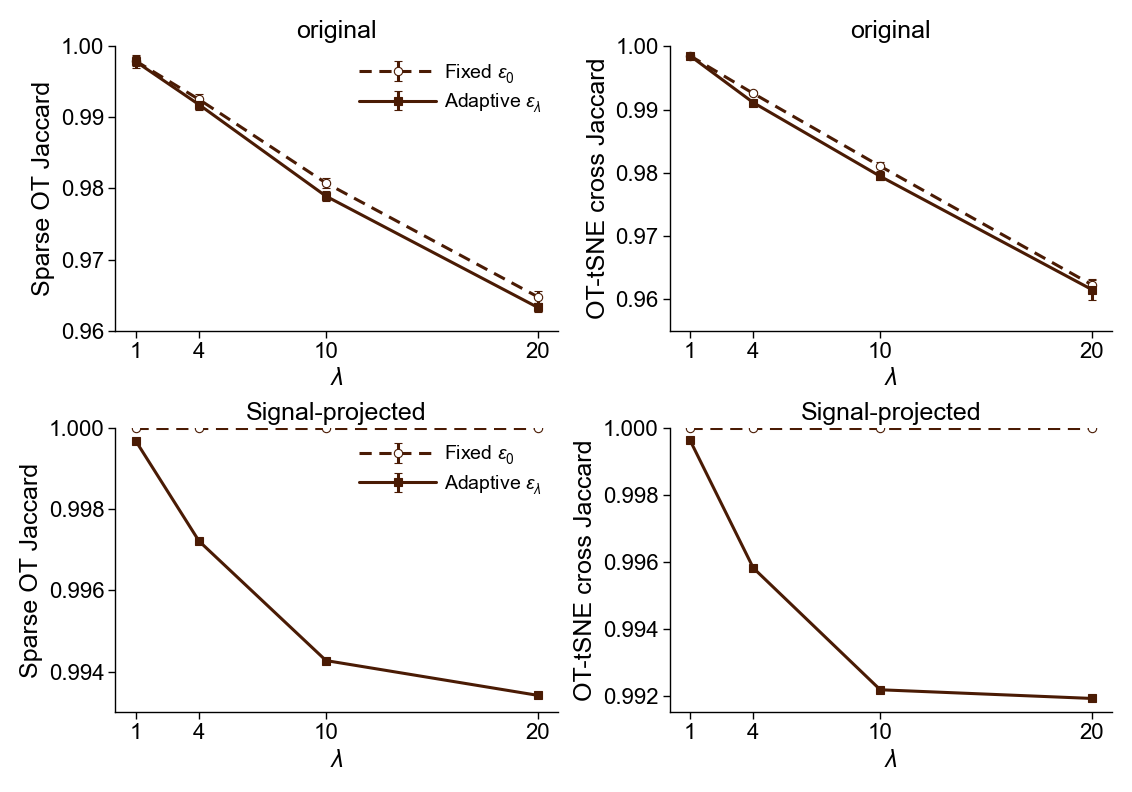

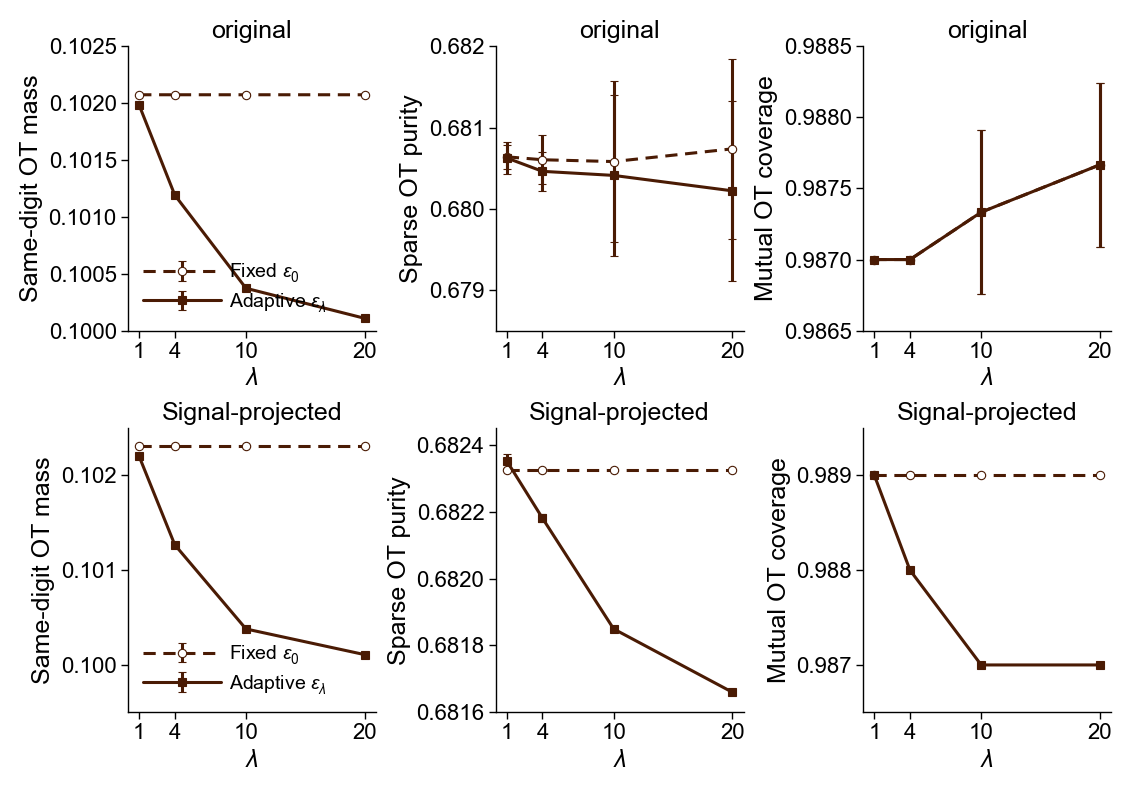

In [24]:
jaccard_columns = [c for c in affinity if c.endswith("_jaccard_to_lambda0")]
assert affinity[jaccard_columns].ge(0).all().all() and affinity[jaccard_columns].le(1).all().all()
assert affinity.loc[affinity.magnitude == 0, jaccard_columns].eq(1).all().all()
display(affinity.loc[affinity.magnitude == max(config.corruption.magnitudes)]
    .groupby(["mode", "epsilon_policy", "rel_reg"])[["shared_or_jaccard_to_lambda0", "ot_tsne_cross_jaccard_to_lambda0"]].mean().round(3))
for rel_reg in config.ot.rel_reg:
    selected = affinity.loc[np.isclose(affinity.rel_reg, rel_reg)]
    print(f"Cross-batch supports · rel_reg={rel_reg:g}")
    ablation_curves(selected, [("shared_or_jaccard_to_lambda0", "Sparse OT Jaccard"),
        ("ot_tsne_cross_jaccard_to_lambda0", "OT-tSNE cross Jaccard")], bounded=True)
    plt.show()
    ablation_curves(selected, [("raw_same_digit_mass_fraction", "Same-digit OT mass"),
        ("eot_shared_or_digit_purity", "Sparse OT purity"),
        ("eot_mutual_and_nonempty_row_fraction", "Mutual OT coverage")], bounded=True)
    plt.show()

### kNN coverage and neighborhood preservation
The table reports shared/mutual kNN purity (batch-0 averages), batch-0 mutual coverage, and clean
within-batch neighbor retention, averaged across corruption seeds. Directional coverage and
full per-seed metrics remain available in the saved diagnostics.


In [25]:
display(
    sweep_only(knn).groupby(["mode", "magnitude"])[[
        "shared_correct_class_neighbor_fraction",
        "mutual_correct_class_neighbor_fraction",
        "mutual_nonempty_row_fraction",
        "within_batch_knn_edge_preservation",
    ]].mean().round(3)
)

shared_correct_class_neighbor_fraction  \
mode      magnitude                                           
original  1.0                                         0.661   
          4.0                                         0.422   
          10.0                                        0.195   
          20.0                                        0.113   
projected 1.0                                         0.674   
          4.0                                         0.425   
          10.0                                        0.196   
          20.0                                        0.113   

                     mutual_correct_class_neighbor_fraction  \
mode      magnitude                                           
original  1.0                                         0.815   
          4.0                                         0.702   
          10.0                                        0.500   
          20.0                                        0.343   
projected 1.0                                         0.811   
          4.0                                         0.688   
          10.0                                        0.494   
          20.0                                        0.344   

                     mutual_nonempty_row_fraction  \
mode      magnitude                                 
original  1.0                               0.983   
          4.0                               0.566   
          10.0                              0.160   
          20.0                              0.107   
projected 1.0                               0.989   
          4.0                               0.569   
          10.0                              0.166   
          20.0                              0.109   

                     within_batch_knn_edge_preservation  
mode      magnitude                                      
original  1.0                                     0.903  
          4.0                                     0.720  
          10.0                                    0.707  
          20.0                                    0.707  
projected 1.0                                     0.903  
          4.0                                     0.728  
          10.0                                    0.716  
          20.0                                    0.716

### Receiving-side hubness and coverage (cross-batch k=15)
For each receiving point j, count distinct opposite-batch senders: Nₖ(j). Histograms at λ=10
normalize each graph/batch/seed by its own mean, including zero-degree points. The y-axis
is logarithmic to show sparse tails; the x-axis stays linear so anti-hubs at zero remain visible. Tables report
anti-hub fraction, maximum occurrence, and population skewness (undefined for constant counts).
The λ=10 summary averages anti-hub fractions/skewness over seeds and takes the largest
per-seed maximum. Raw per-seed values are saved. Coverage is the fraction with Nₖ≥1,
with mean ± sample SD over the existing corruption seeds.
Directed 0→1 has receiving batch 1 only; directed 1→0 has receiving batch 0 only.

We use the same input representation and Euclidean neighbors as the purity analysis. Mutual/shared
kNN are the intersection/union of both directed selections. Sparsified OT is the **cross-batch
row-top-15/column-top-15 union used in the affinity purity comparison**, at the diagnostic rel_reg
for each ε policy. This is not the embedding's four-block effective-k graph. Symmetrized shared kNN
and this OT support guarantee positive degree on both sides: their coverage is structurally one,
although their in-degree distributions can be uneven. Heavy tails or concentration near 1 are
hypotheses to inspect, not imposed results. Independent normalization avoids conflating unequal
batch sizes with hubness; no within-batch edges or affinity weights enter the counts.

`COMPUTE_HUBNESS=True` computes only these graph diagnostics, including from a saved construction;
it does not run embeddings or change seeds/λ values. Otherwise read a compatible saved diagnostic.
MultiMAP connectivities and Scanorama MNN pairs were not retained in the existing artifact
interfaces, so those optional receiving-graph diagnostics are skipped (coordinates are not graphs).

This ablation displays **both** fixed-at-λ=0 and adaptive ε separately at the selected
rel_reg. kNN controls are identical across policies. Coverage aggregation filters by policy
before taking seed means/SDs, so it never mixes fixed and adaptive graph measurements.


**Why two batches for an undirected graph?** For a cross-batch support matrix $A$, batch-0 degrees
are $d_i^{(0)}=\sum_j A_{ij}$ and batch-1 degrees are $d_j^{(1)}=\sum_i A_{ij}$.
Each undirected edge contributes one neighbor to each endpoint. The histograms show these two
node populations separately, not a pooled distribution and not two contributions to one node.
For directed $0\to1$ kNN only batch 1 receives; for $1\to0$ only batch 0 receives.

**Coverage** for batch $b$ is $\frac{1}{n_b}\sum_i\mathbf{1}[d_i^{(b)}\ge1]$;
coverage 0.8 means 20% of that batch has no cross-batch neighbor. It measures contact, not digit
correctness or uniformity of degrees. Shared kNN (union of both directions) and Sparse OT
(union of row/column top-15 supports) cover both batches by construction. Mutual kNN can leave
isolated nodes. Thus flat coverage 1 for shared/Sparse OT is expected; the degree histograms
show whether many edges nevertheless concentrate on a few nodes. Curves show mean ± SD over
corruption seeds, separately by receiving batch. MultiMAP connectivities and Scanorama MNN pairs
are not present in the saved artifacts, so these methods are omitted here.


In [26]:
from ne_aligned_utils.evaluation.hubness import (
    cross_batch_occurrences, occurrence_statistics, summarize_coverage, restore_saved_construction,
)
from ne_aligned_utils.paper.figures.hubness import occurrence_histograms, receiving_coverage_figure

COMPUTE_HUBNESS = RUN_EXPERIMENT  # Reuses this ablation's plan cache; no new embedding runs.
HUBNESS_K, HUBNESS_MAGNITUDE = 15, 10.0
hubness_dir = experiment.run_dir / "ablation/hubness"
hubness_settings = dict(schema="paired_eps0_cross_batch_topk_union_v1", k=HUBNESS_K,
    rel_reg=plot_config.rel_reg, epsilon_policies=list(config.ot.epsilon_policies),
    histogram_magnitude=HUBNESS_MAGNITUDE,
    construction_sha256=json.loads((experiment.run_dir / "config.json").read_text())["construction_sha256"])
hubness_stats = hubness_points = None

In [27]:
if COMPUTE_HUBNESS:
    prepare_cached_plan_inputs(plot_config.rel_reg)
    hubness_records, histogram_records = [], []
    for mode in config.data.modes:
        for corruption_seed in config.corruption.corruption_seeds:
            for magnitude in config.corruption.magnitudes:
                x0, x1 = experiment.make_batches(mode, magnitude, corruption_seed)
                forward = experiment.directed_knn(x0, x1, HUBNESS_K)
                backward = experiment.directed_knn(x1, x0, HUBNESS_K)
                for policy in config.ot.epsilon_policies:
                    plan = experiment.compute_policy_plan(x0, x1, mode, plot_config.rel_reg, policy)
                    points = cross_batch_occurrences(forward, backward,
                        experiment.rectangular_topk_support(plan, HUBNESS_K, axis=1),
                        experiment.rectangular_topk_support(plan, HUBNESS_K, axis=0))
                    metadata = dict(mode=mode, magnitude=magnitude, corruption_seed=corruption_seed,
                                    k=HUBNESS_K, rel_reg=plot_config.rel_reg, epsilon_policy=policy)
                    hubness_records.append(occurrence_statistics(points).assign(**metadata))
                    if magnitude == HUBNESS_MAGNITUDE:
                        histogram_records.append(points.assign(**metadata))
            print(f"Paired receiving diagnostics: {mode}, corruption seed {corruption_seed}")
    hubness_stats = pd.concat(hubness_records, ignore_index=True)
    hubness_points = (pd.concat(histogram_records, ignore_index=True) if histogram_records
                      else pd.DataFrame(columns=[*points.columns, *metadata]))
    hubness_dir.mkdir(parents=True, exist_ok=True)
    hubness_stats.to_csv(hubness_dir / "receiving_coverage_metrics_raw.csv", index=False)
    hubness_points.to_csv(hubness_dir / "k_occurrence_lambda10.csv", index=False)
    hubness_summary = pd.concat([summarize_coverage(part).assign(epsilon_policy=policy)
        for policy, part in hubness_stats.groupby("epsilon_policy")], ignore_index=True)
    hubness_summary.to_csv(hubness_dir / "receiving_coverage_metrics_summary.csv", index=False)
    (hubness_dir / "config.json").write_text(json.dumps(hubness_settings, indent=2, sort_keys=True))
elif (hubness_dir / "config.json").is_file():
    if json.loads((hubness_dir / "config.json").read_text()) != hubness_settings:
        raise ValueError("Saved hubness selection differs; explicitly recompute this diagnostic.")
    hubness_stats = pd.read_csv(hubness_dir / "receiving_coverage_metrics_raw.csv")
    hubness_points = pd.read_csv(hubness_dir / "k_occurrence_lambda10.csv")
else:
    print("No paired hubness cache yet. Set COMPUTE_HUBNESS=True to use this run's stored plans.")

Receiving diagnostics · Fixed ε at λ=0 · rel_reg=1


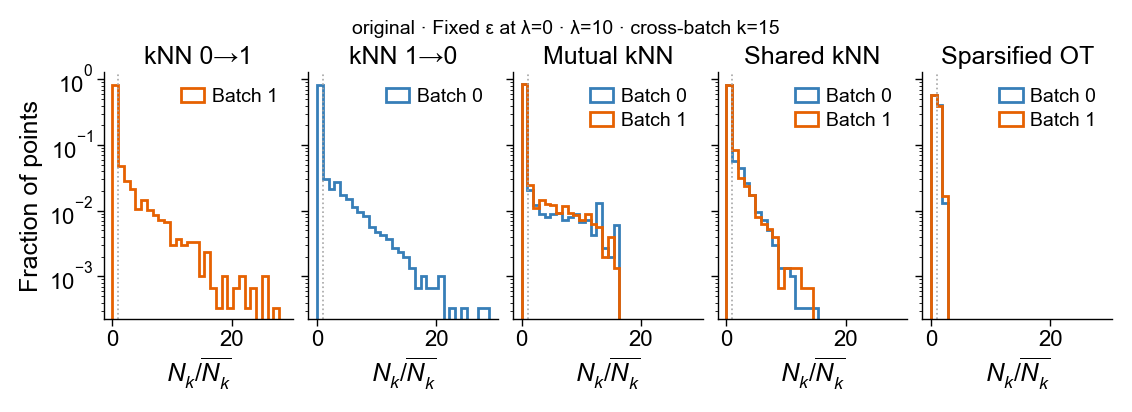

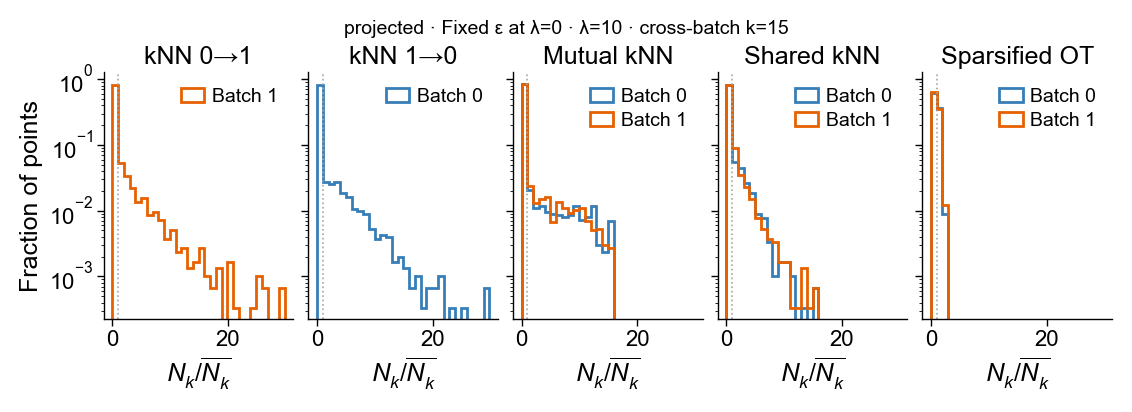

anti_hub_fraction  max_k_occurrence  \
mode      graph      receiving_batch                                        
original  knn_0_to_1 1                            0.729               408   
          knn_1_to_0 0                            0.736               429   
          mutual_knn 0                            0.840                15   
                     1                            0.823                15   
          shared_knn 0                            0.000               431   
                     1                            0.000               412   
          sparse_ot  0                            0.000                54   
                     1                            0.000                49   
projected knn_0_to_1 1                            0.728               439   
          knn_1_to_0 0                            0.736               443   
          mutual_knn 0                            0.834                15   
                     1                            0.821                15   
          shared_knn 0                            0.000               444   
                     1                            0.000               439   
          sparse_ot  0                            0.000                52   
                     1                            0.000                47   

                                      skewness  
mode      graph      receiving_batch            
original  knn_0_to_1 1                   4.331  
          knn_1_to_0 0                   3.900  
          mutual_knn 0                   3.205  
                     1                   2.973  
          shared_knn 0                   3.996  
                     1                   4.471  
          sparse_ot  0                   1.637  
                     1                   1.562  
projected knn_0_to_1 1                   4.603  
          knn_1_to_0 0                   3.962  
          mutual_knn 0                   3.109  
                     1                   2.940  
          shared_knn 0                   4.087  
                     1                   4.774  
          sparse_ot  0                   1.566  
                     1                   1.501

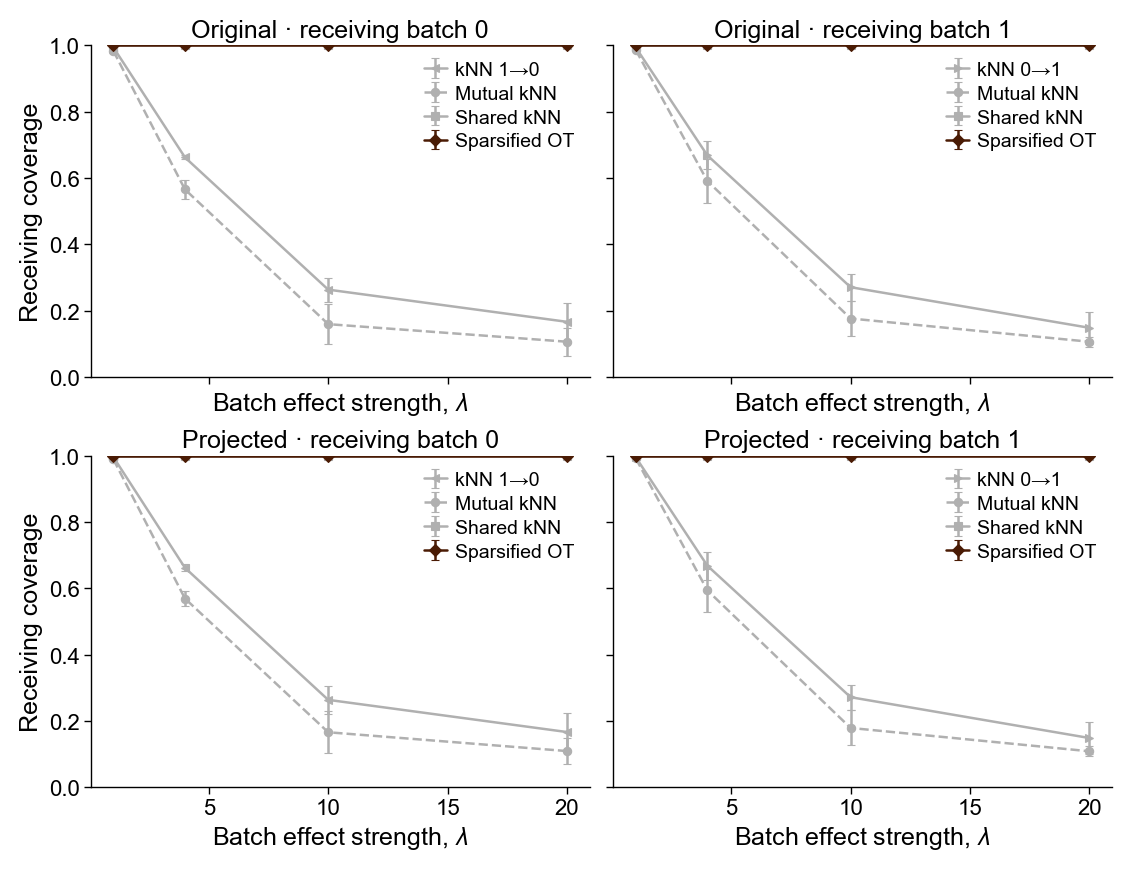

Receiving diagnostics · Adaptive ε · rel_reg=1


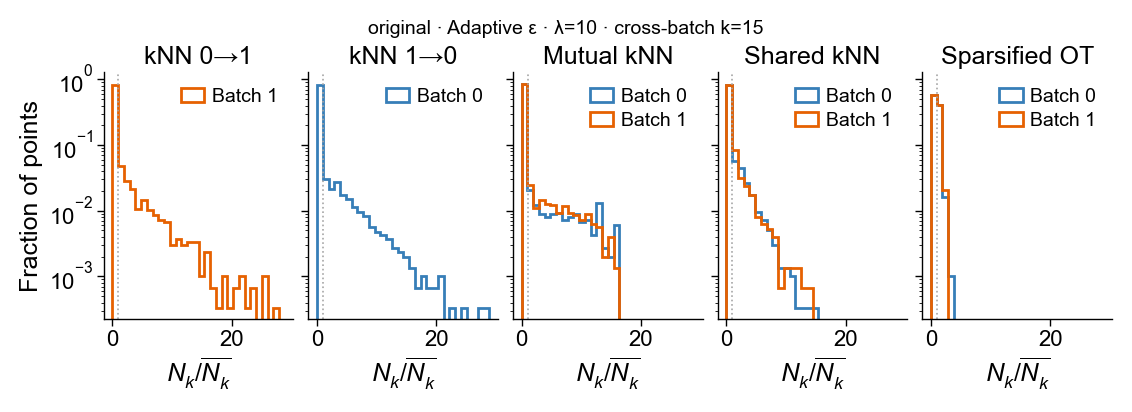

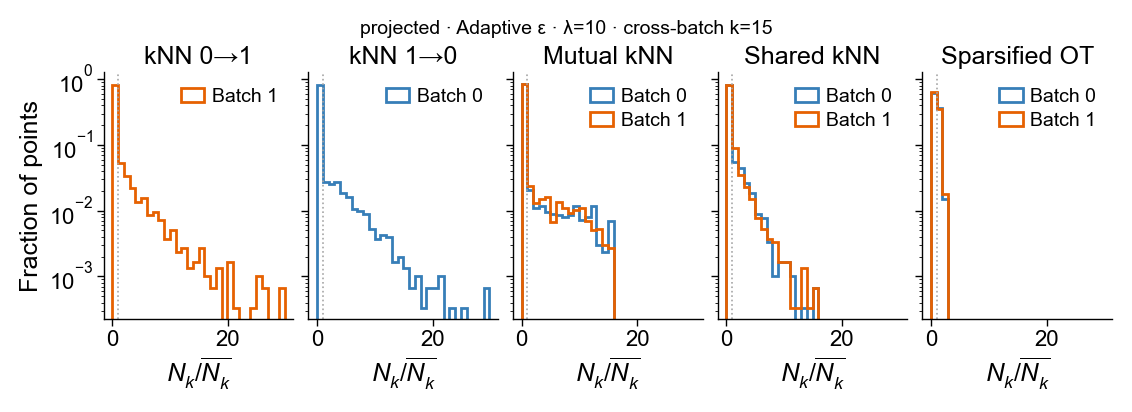

anti_hub_fraction  max_k_occurrence  \
mode      graph      receiving_batch                                        
original  knn_0_to_1 1                            0.729               408   
          knn_1_to_0 0                            0.736               429   
          mutual_knn 0                            0.840                15   
                     1                            0.823                15   
          shared_knn 0                            0.000               431   
                     1                            0.000               412   
          sparse_ot  0                            0.000                64   
                     1                            0.000                60   
projected knn_0_to_1 1                            0.728               439   
          knn_1_to_0 0                            0.736               443   
          mutual_knn 0                            0.834                15   
                     1                            0.821                15   
          shared_knn 0                            0.000               444   
                     1                            0.000               439   
          sparse_ot  0                            0.000                64   
                     1                            0.000                57   

                                      skewness  
mode      graph      receiving_batch            
original  knn_0_to_1 1                   4.331  
          knn_1_to_0 0                   3.900  
          mutual_knn 0                   3.205  
                     1                   2.973  
          shared_knn 0                   3.996  
                     1                   4.471  
          sparse_ot  0                   2.029  
                     1                   1.820  
projected knn_0_to_1 1                   4.603  
          knn_1_to_0 0                   3.962  
          mutual_knn 0                   3.109  
                     1                   2.940  
          shared_knn 0                   4.087  
                     1                   4.774  
          sparse_ot  0                   1.973  
                     1                   1.777

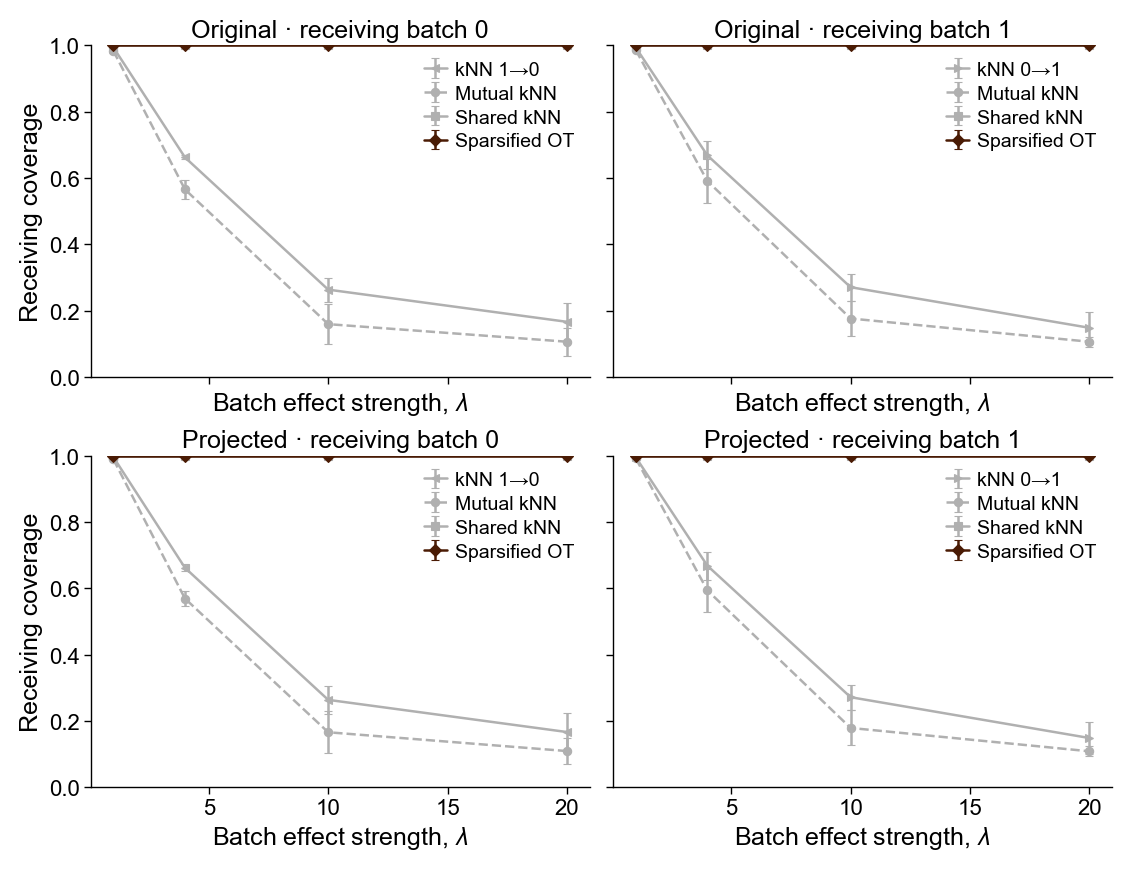

Per-policy statistics, λ=10 counts, seed summaries and settings: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__c70fb5e4/ablation/hubness


In [28]:
if hubness_stats is not None:
    for policy in config.ot.epsilon_policies:
        label = "Fixed ε at λ=0" if policy == "fixed_at_lambda_0" else "Adaptive ε"
        print(f"Receiving diagnostics · {label} · rel_reg={plot_config.rel_reg:g}")
        selected_stats = sweep_only(hubness_stats.loc[hubness_stats.epsilon_policy == policy])
        selected_points = hubness_points.loc[hubness_points.epsilon_policy == policy]
        if not selected_points.empty:
            for mode in config.data.modes:
                occurrence_histograms(selected_points.loc[selected_points["mode"] == mode],
                    title=f"{mode} · {label} · λ=10 · cross-batch k=15")
                plt.show()
            display(selected_stats.loc[selected_stats.magnitude == HUBNESS_MAGNITUDE]
                .groupby(["mode", "graph", "receiving_batch"])
                .agg(anti_hub_fraction=("anti_hub_fraction", "mean"),
                     max_k_occurrence=("max_k_occurrence", "max"), skewness=("skewness", "mean"))
                .round(3))
        fig = receiving_coverage_figure(summarize_coverage(selected_stats), config.data.modes)
        for ax in fig.axes:
            rounded_diagnostic_ylim(ax, probability=True)
        plt.show()
    print(f"Per-policy statistics, λ=10 counts, seed summaries and settings: {hubness_dir}")

## 8. Embedding experiment
Each method definition below creates its own explicit method metadata and invokes the repository
method API through the strict cache utility. Compatible coordinates resume; incompatible sidecars
raise an error. Purity uses the current macro-by-label metric with a 15-neighbor cap; kBET uses
the configured neighborhood and digit conditioning. Full per-seed tables are saved.
The final short loop applies these definitions across the configured grid.

In [29]:
def score_embedding(meta, embedding, runtime, path, display_method):
    batch_ids = np.r_[np.zeros(len(experiment.labels0), int), np.ones(len(experiment.labels1), int)]
    return {
        **meta,
        "display_method": display_method,
        "purity": compute_neighbor_purity(embedding, experiment.labels),
        "kbet": compute_kbet(embedding, batch_ids, experiment.labels, k=config.evaluation.kbet_k),
        "runtime_seconds": runtime,
        "cache_path": str(path),
    }

### OT-tSNE
Use the balanced rectangular plan, configured effective k, random initialization, and each ε/rel_reg
combination. Plan reuse across embedding seeds avoids solving the same transport problem again.

In [30]:
def ot_embeddings(x0, x1, mode, magnitude, corruption_seed, embedding_seed):
    records = []
    for rel_reg in experiment.config.ot.rel_reg:
        for epsilon_policy in experiment.config.ot.epsilon_policies:
            plan_key = (mode, corruption_seed, magnitude, rel_reg, epsilon_policy)
            if plan_key not in embedding_plan_cache:
                embedding_plan_cache[plan_key] = experiment.compute_policy_plan(x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=True)
            plan, artifacts = embedding_plan_cache[plan_key]
            display_method = f'OT-tSNE ({epsilon_policy}, rel_reg={rel_reg:g})'
            path = experiment.cache_path(mode, magnitude, 'ot', 'tsne', corruption_seed, embedding_seed, epsilon_policy, rel_reg, experiment.config.ot.ot_effective_k)
            meta = dict(mode=mode, magnitude=magnitude, method='ot', backend='tsne', corruption_seed=corruption_seed, embedding_seed=embedding_seed, rel_reg=rel_reg, epsilon=float(artifacts['epsilon']), epsilon_policy=epsilon_policy, effective_k=experiment.config.ot.ot_effective_k, n_jobs=TSNE_N_JOBS)
            embedding, runtime = experiment.load_or_compute(path, lambda plan=plan, embedding_seed=embedding_seed, x0=x0, x1=x1: compute_ot_tsne_embedding_from_plan(plan, effective_k=experiment.config.ot.ot_effective_k, random_state=embedding_seed, n_epochs=experiment.config.embedding.n_epochs, early_exaggeration_iter=experiment.config.embedding.early_exaggeration_iter, init='random', backend='tsne', x_joint=np.vstack([x0, x1]), n_jobs=TSNE_N_JOBS), meta)
            records.append(score_embedding(meta, embedding, runtime, path, display_method))
    return records

### Scanorama + t-SNE
Integrate in 50 dimensions with exact matching (`approx=False`), then run t-SNE with perplexity 30
and the configured embedding seed and iteration count.

In [31]:
def scanorama_embeddings(x0, x1, mode, magnitude, corruption_seed, embedding_seed):
    records = []
    if experiment.config.competitors.run_scanorama_50_tsne:
        display_method, key = ('Scanorama + t-SNE (50d)', 'scanorama-50-tsne')
        path = experiment.cache_path(mode, magnitude, key, 'tsne', corruption_seed, embedding_seed)
        meta = dict(mode=mode, magnitude=magnitude, method=key, backend='tsne', corruption_seed=corruption_seed, embedding_seed=embedding_seed, epsilon_policy=None, rel_reg=None, effective_k=None, integration_dim=50, perplexity=30.0, n_epochs=experiment.config.embedding.n_epochs)
        embedding, runtime = experiment.load_or_compute(path, lambda embedding_seed=embedding_seed, x0=x0, x1=x1: compute_scanorama_then_tsne_embedding_from_arrays(x0, x1, scanorama_dim=50, random_state=embedding_seed, perplexity=30.0, scanorama_kwargs={'approx': False}, n_iter=experiment.config.embedding.n_epochs, early_exaggeration_iter=experiment.config.embedding.early_exaggeration_iter, backend='tsne', n_jobs=TSNE_N_JOBS), meta)
        records.append(score_embedding(meta, embedding, runtime, path, display_method))
    return records

### MultiMAP
Choose `multimap_profile="default"` or `"k15"` in the global configuration. Default omits
`n_neighbors`; k15 sets only `n_neighbors=15`. All other MultiMAP parameters use wrapper/native
defaults, including preprocessing and optimization length. The embedding seed remains explicit.
These profiles differ from the earlier controlled runs; old embeddings are not reused.

The subprocess preserves float64 for native scaling and zeros exactly constant columns
within each batch. This prevents variance underflow/cancellation from producing NaNs;
all features are retained. No algorithm hyperparameters are added.

In [32]:
def multimap_embeddings(x0, x1, mode, magnitude, corruption_seed, embedding_seed):
    records = []
    if config.competitors.run_multimap:
        profile = experiment.config.competitors.multimap_profile
        k = 15 if profile == "k15" else None
        backend = "native-defaults"
        display_method = "MultiMAP · k=15" if k is not None else "MultiMAP · default"
        path = experiment.cache_path(
            mode, magnitude, "multimap", backend, corruption_seed, embedding_seed, k=k
        )
        meta = dict(
            mode=mode,
            magnitude=magnitude,
            method="multimap",
            backend=backend,
            corruption_seed=corruption_seed,
            embedding_seed=embedding_seed,
            epsilon_policy=None,
            rel_reg=None,
            effective_k=k,
            preprocessing="default",
            multimap_profile=profile,
        )
        kwargs = {} if k is None else {"n_neighbors": k}
        embedding, runtime = experiment.load_or_compute(
            path,
            partial(
                compute_multimap_embedding_from_arrays,
                x0,
                x1,
                random_state=embedding_seed,
                **kwargs,
            ),
            meta,
        )
        records.append(score_embedding(meta, embedding, runtime, path, display_method))
    return records

In [33]:
if RUN_EXPERIMENT:
    records, embedding_plan_cache = ([], {})
    for mode in config.data.modes:
        for corruption_seed in config.corruption.corruption_seeds:
            for magnitude in config.corruption.magnitudes:
                x0, x1 = experiment.make_batches(mode, magnitude, corruption_seed)
                embedding_plan_cache.clear()
                for embedding_seed in config.embedding.embedding_seeds:
                    for method in (ot_embeddings, scanorama_embeddings, multimap_embeddings):
                        records.extend(method(x0, x1, mode, magnitude, corruption_seed, embedding_seed))
                print(f'Completed {mode}, corruption seed {corruption_seed}, λ={magnitude:g}')
    experiment.results = label_methods(pd.DataFrame(records))
    experiment.save_stage('embedding')
    gallery0, gallery1 = experiment.make_batches('original', 10.0, 0)
    gallery_path = experiment.cache_path('original', 10.0, 'joint-tsne', 'tsne', 0, 0)
    gallery_metadata = dict(method='joint-tsne', magnitude=10.0, corruption_seed=0, embedding_seed=0, perplexity=30.0, pca_components=50, backend='tsne', n_iter=config.embedding.n_epochs, early_exaggeration_iter=config.embedding.early_exaggeration_iter, n_jobs=TSNE_N_JOBS)
    experiment.load_or_compute(gallery_path, partial(compute_tsne_embedding_from_arrays, gallery0, gallery1, random_state=0, perplexity=30.0, pca_components=50, n_iter=config.embedding.n_epochs, early_exaggeration_iter=config.embedding.early_exaggeration_iter, n_jobs=TSNE_N_JOBS), gallery_metadata)
    results = experiment.results
else:
    results = runs.metrics
print(f'{len(results)} per-seed embedding evaluations; complete table saved on disk.')

540 per-seed embedding evaluations; complete table saved on disk.


### Paper panel C: representative embeddings
Read the saved λ=10, corruption/embedding-seed-0 coordinates, including the joint t-SNE control.
The same paper gallery draws batch-colored and digit-colored rows. This preview uses no new fits.

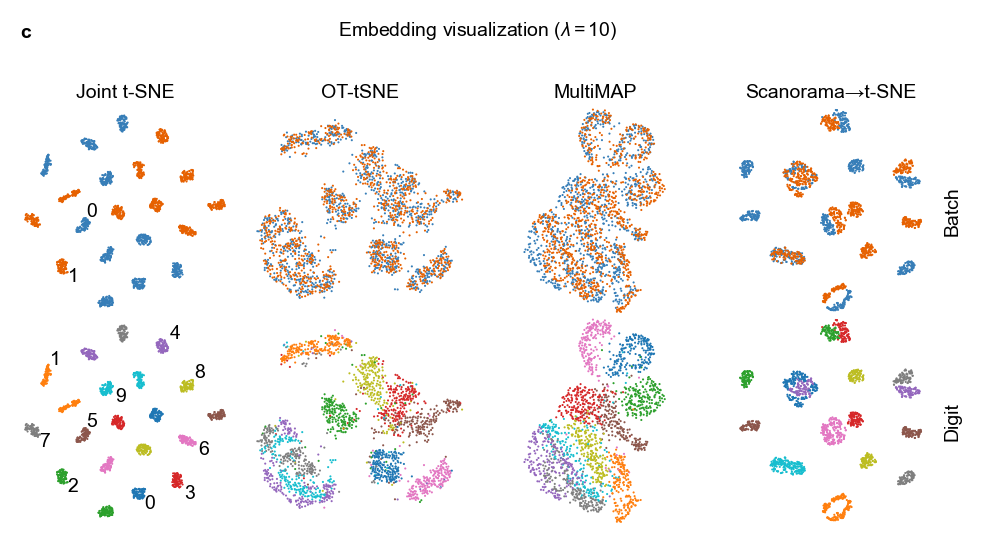

In [34]:
# The structured coordinate path is independent of embedding method parameters.
joint_path = (
    experiment.run_dir / "original/embeddings/joint_tsne/lambda_10/"
    "corruption_seed_0/embedding_seed_0.npz"
)
unintegrated = saved_synthetic.load_coordinates(joint_path, len(labels0) + len(labels1))
with plt.rc_context({"figure.constrained_layout.use": False}):
    fig = plt.figure(figsize=layout.full_width(3.0))
    fig.subplots_adjust(left=0.04, right=0.96, bottom=0.06, top=0.88)
    grid = fig.add_gridspec(1, 1)
    drawing.representative_embeddings(
        fig,
        grid[0],
        experiment.run_dir / "original",
        labels0,
        labels1,
        unintegrated=unintegrated,
        band=(0.08, 0.78),  # reserve a separate line for the gallery heading
        letter="C",
        centred=True,
    )
    drawing.lay_out_panels(fig)
    plt.show()

## 9. Aggregate and inspect results
Average embedding seeds within each corruption seed first; only then compute means and sample SD
across corruption draws. A single draw has undefined SD, rather than a fabricated zero.
Stable `method_id` values identify configurations; display labels and parameter columns stay separate.
Raw evaluations, per-corruption summaries, and aggregate summaries are separate CSV artifacts.

In [35]:
if RUN_EXPERIMENT:
    if "preprocessing" not in experiment.results:
        experiment.results["preprocessing"] = None
    experiment.per_corruption_summary = (
        experiment.results.groupby(
            [
                "mode",
                "magnitude",
                "method_id",
                "method",
                "display_method",
                "epsilon_policy",
                "rel_reg",
                "effective_k",
                "preprocessing",
                "corruption_seed",
            ],
            dropna=False,
        )
        .agg(
            purity=("purity", "mean"),
            purity_embedding_sd=("purity", "std"),
            kbet=("kbet", "mean"),
            kbet_embedding_sd=("kbet", "std"),
            n_embedding_seeds=("embedding_seed", "size"),
        )
        .reset_index()
    )
    experiment.summary = (
        experiment.per_corruption_summary.groupby(
            [
                "mode",
                "magnitude",
                "method_id",
                "method",
                "display_method",
                "epsilon_policy",
                "rel_reg",
                "effective_k",
                "preprocessing",
            ],
            dropna=False,
        )
        .agg(
            purity=("purity", "mean"),
            purity_std=("purity", "std"),
            purity_embedding_sd_mean=("purity_embedding_sd", "mean"),
            kbet=("kbet", "mean"),
            kbet_std=("kbet", "std"),
            kbet_embedding_sd_mean=("kbet_embedding_sd", "mean"),
            n_corruption_seeds=("corruption_seed", "size"),
        )
        .reset_index()
    )
    experiment.save_stage("summary")
else:
    print("Using saved artifacts for this stage.")

Using saved artifacts for this stage.


In [36]:
# Reload the explicit saved run after either execution mode.
runs = load_selected_ablation()
summary = runs.summary
print("Saved run:", experiment.run_dir)

Saved run: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__c70fb5e4


### Embedding purity and batch mixing
Compare saved OT-tSNE, Scanorama+t-SNE, and MultiMAP results for each configured rel_reg.
Average embedding seeds within each corruption seed, then show mean ± SD across corruption seeds.
Fixed and adaptive OT use matched embedding seeds; λ=0 is excluded from the sweep display.
The compact table shows the first and last experimental λ values; full tables remain saved.


Fresh embeddings · rel_reg=1


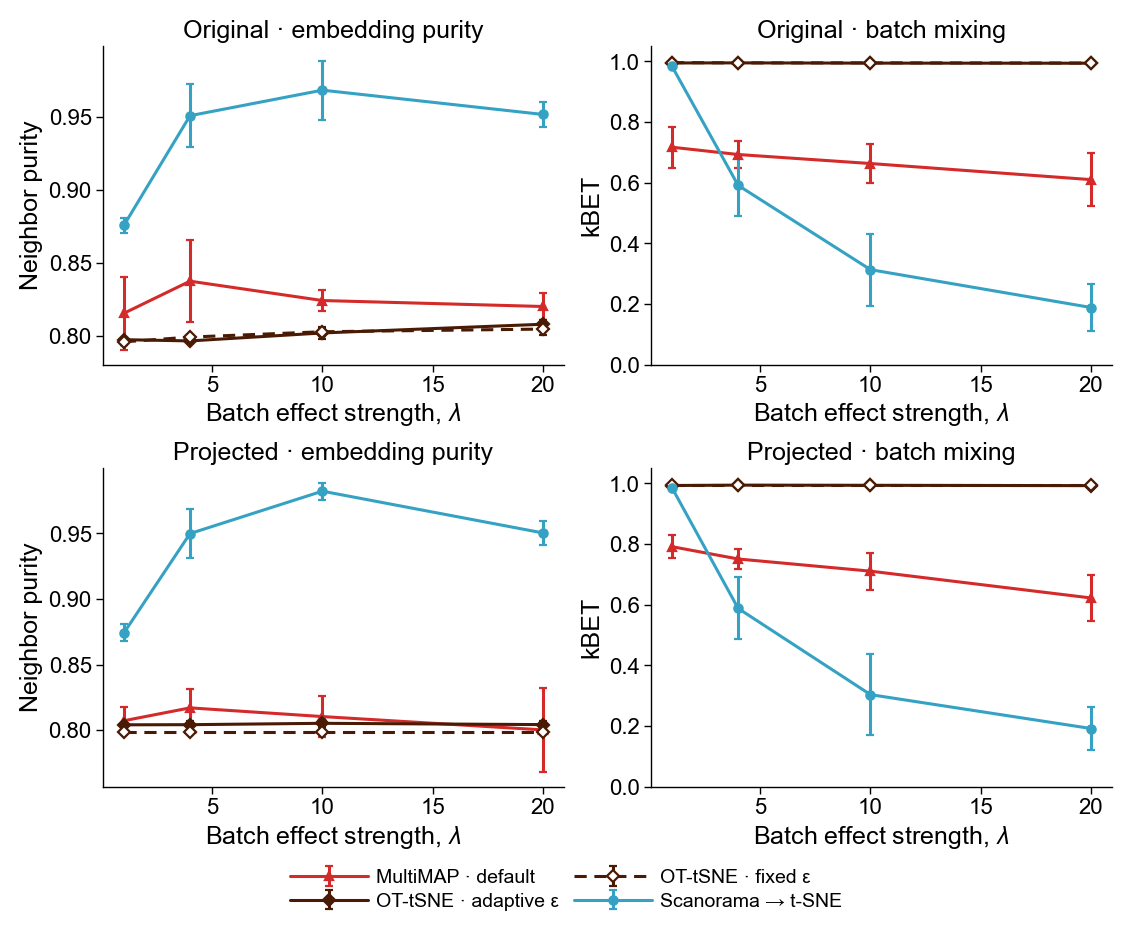

Fresh embeddings · rel_reg=10


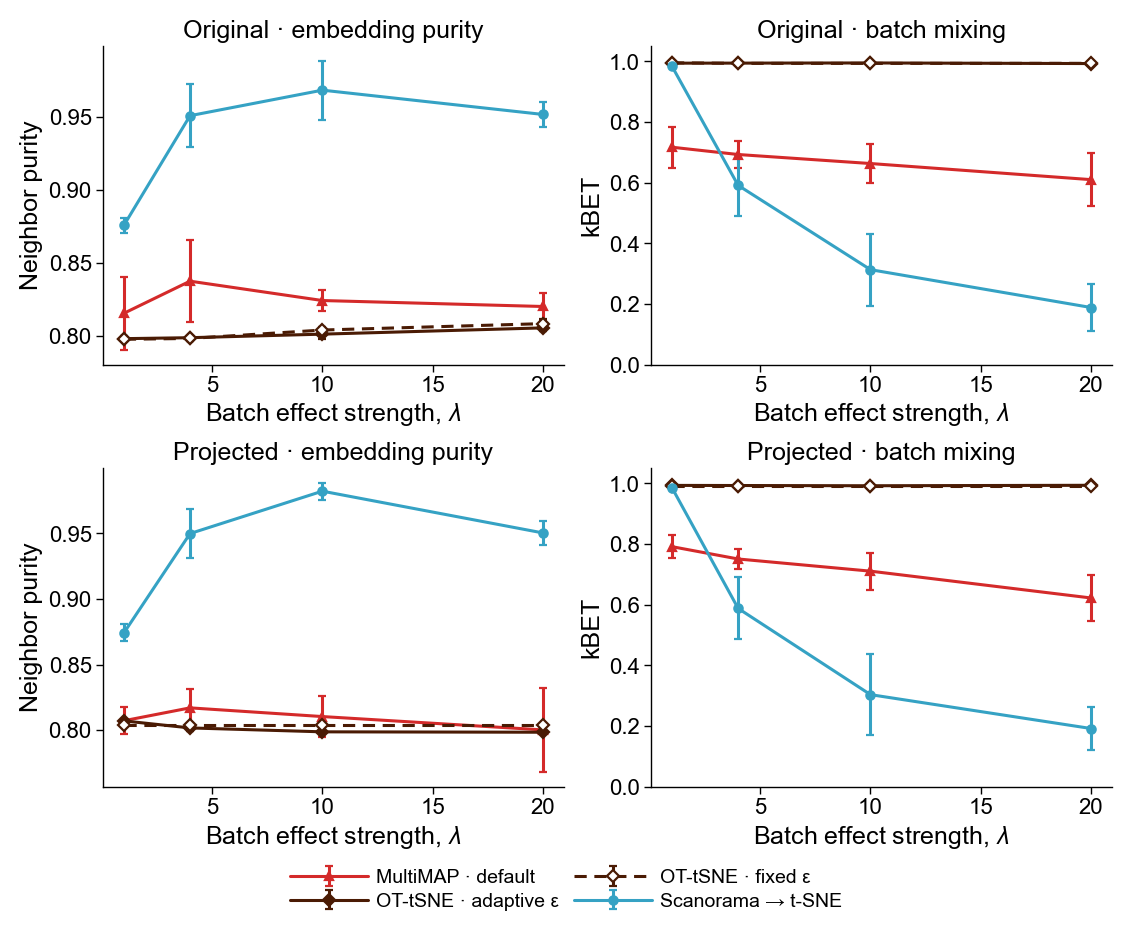

,mode,magnitude,display_method,purity,purity_std,purity_embedding_sd_mean,kbet,kbet_std,kbet_embedding_sd_mean
8,original,1.0,OT-tSNE · adaptive ε · rel_reg=1,0.798,0.001,0.005,0.994,0.001,0.001
10,original,1.0,OT-tSNE · fixed ε · rel_reg=1,0.796,0.002,0.003,0.995,0.001,0.002
26,original,20.0,OT-tSNE · adaptive ε · rel_reg=1,0.808,0.003,0.006,0.993,0.002,0.002
28,original,20.0,OT-tSNE · fixed ε · rel_reg=1,0.805,0.004,0.006,0.994,0.002,0.002
38,projected,1.0,OT-tSNE · adaptive ε · rel_reg=1,0.804,0.000,0.002,0.992,0.000,0.001
40,projected,1.0,OT-tSNE · fixed ε · rel_reg=1,0.799,0.000,0.001,0.994,0.000,0.001
56,projected,20.0,OT-tSNE · adaptive ε · rel_reg=1,0.804,0.003,0.004,0.992,0.000,0.002
58,projected,20.0,OT-tSNE · fixed ε · rel_reg=1,0.799,0.000,0.001,0.994,0.000,0.001


In [37]:
quality = sweep_only(experiment.summary if RUN_EXPERIMENT else runs.summary)
for rel_reg in config.ot.rel_reg:
    selected = quality.loc[(quality.method != "ot") | np.isclose(quality.rel_reg, rel_reg)]
    print(f"Fresh embeddings · rel_reg={rel_reg:g}")
    # Reuse the repository's method colors, markers and fixed/adaptive line styles.
    from ne_aligned_utils.paper.figures import parallel_synthetic as comparison_drawing
    fig = comparison_drawing.metrics_figure(selected, config.data.modes, rel_reg)
    plt.show()
quality_preview = quality.loc[(quality.method == "ot") &
    np.isclose(quality.rel_reg, plot_config.rel_reg) &
    quality.magnitude.isin([min(DISPLAY_MAGNITUDES), max(DISPLAY_MAGNITUDES)])]
display(quality_preview[["mode", "magnitude", "display_method", "purity", "purity_std",
    "purity_embedding_sd_mean", "kbet", "kbet_std", "kbet_embedding_sd_mean"]].round(3))


## 10. Reproduce the synthetic paper figure from saved results
The explicit run above is reloaded through `paper.inputs.synthetic.load_experiment()`.
`build_variant()` is the same callable used by `scripts/figures/synthetic.py`; no notebook-only
layout exists. It reconstructs the recorded MNIST/PCA for illustration and reads saved coordinates
and metrics. It never fits an integration method.

The current gallery requires λ=10, corruption/embedding seed 0, adaptive ε with rel_reg=1,
the configured MultiMAP profile, and Scanorama. Keep those entries when creating a figure-compatible run.
`SAVE_PAPER_FIGURE=False` previews in a temporary directory; enable the top-level switch to save
under the canonical `results/paper_figures/synthetic_experiment/final/` directory.

Browse `data/construction.npz`, representation-specific `diagnostics/*.csv`,
`metrics/embedding_metrics_{raw,per_corruption,summary}.csv`, and
`embeddings/<method-id>/lambda_*/corruption_seed_*/embedding_seed_*.{npz,json}`.
The manifest stores exact settings; each embedding has a readable metadata sidecar.

Figure input — Original MNIST: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__c70fb5e4/original
Figure input — Projected control: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__c70fb5e4/signal_projected


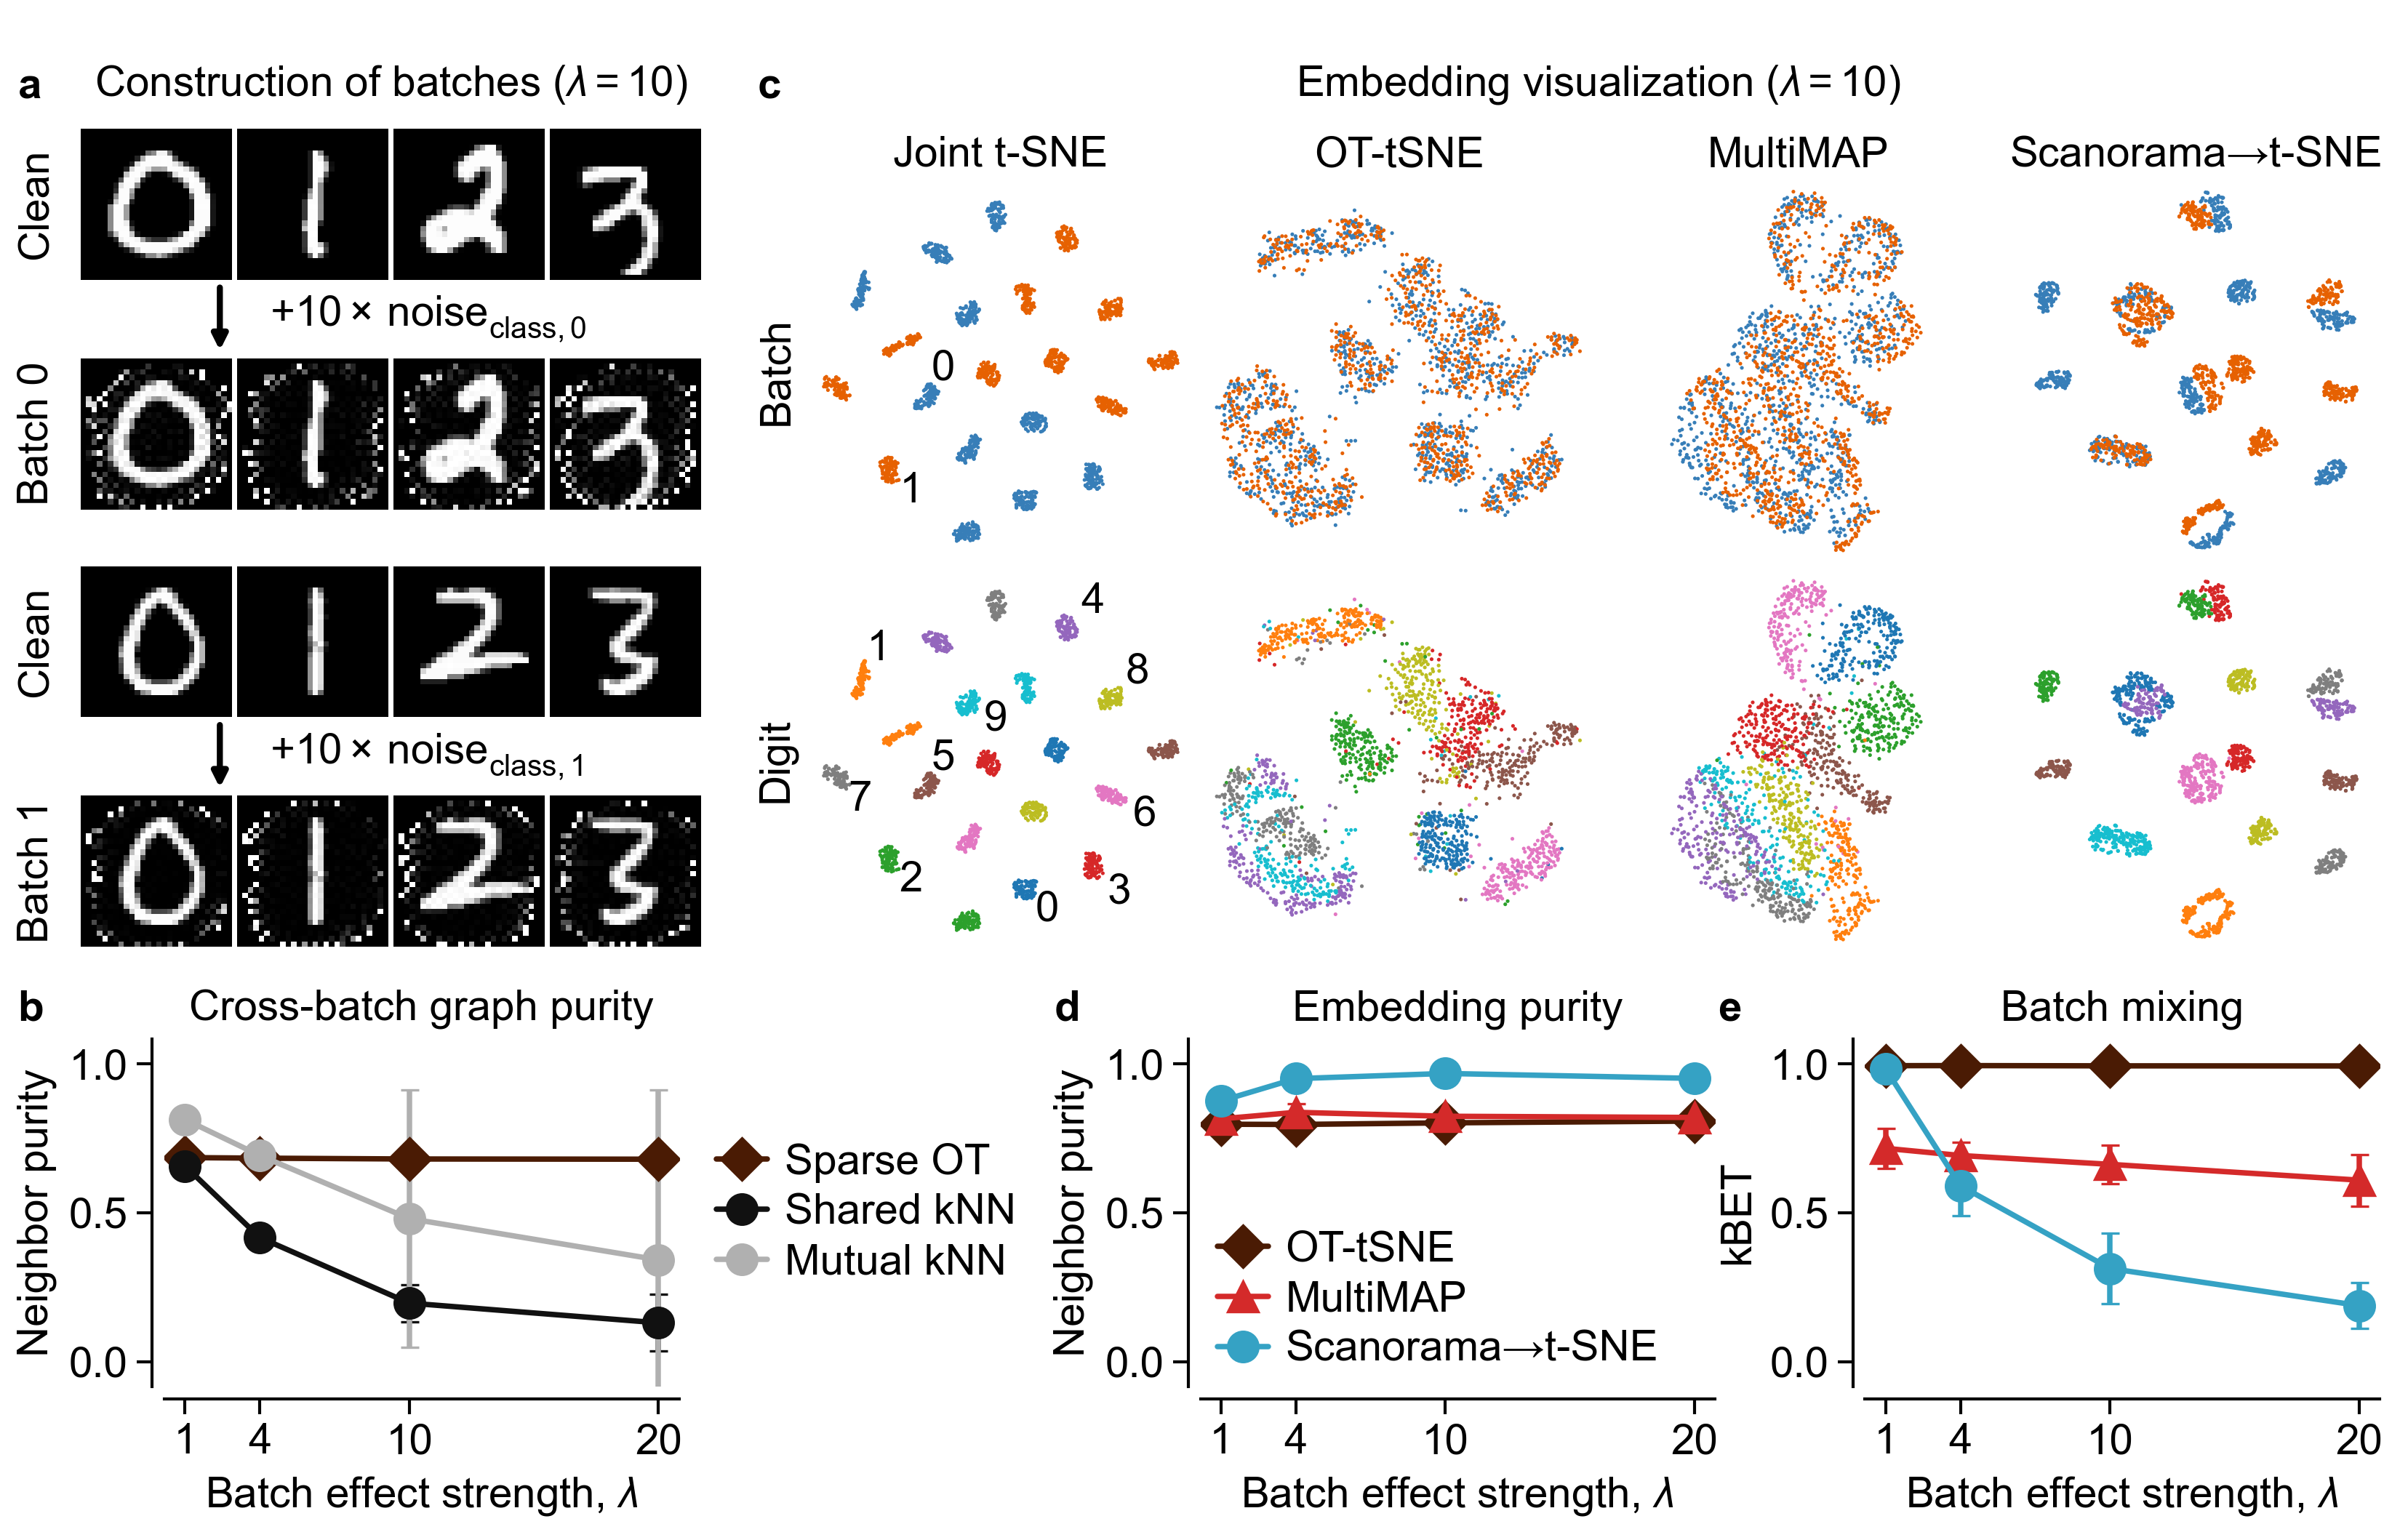

In [38]:
if SMOKE:
    print("Smoke run: full manuscript composite omitted; recorded full-data PCA was retained.")
else:
    from tempfile import TemporaryDirectory
    from ne_aligned_utils.paper import layout
    from ne_aligned_utils.paper.figures.synthetic import PANEL_TITLE_PT

    for mode, directory in runs.run_dirs.items():
        print(f"Figure input — {saved_synthetic.MODE_LABEL[mode]}: {directory}")


    # A display-only view: retain zero plans for the canonical loader's reference checks.
    from dataclasses import replace
    figure_runs = replace(runs,
        configs={mode: {**settings, "magnitudes": DISPLAY_MAGNITUDES} for mode, settings in runs.configs.items()},
        knn=sweep_only(runs.knn), summary=sweep_only(runs.summary))

    def reproduce_paper_figure(output_dir):
        with (
            layout.paper_style(),
            plt.rc_context(
                {
                    key: PANEL_TITLE_PT
                    for key in ("xtick.labelsize", "ytick.labelsize", "legend.fontsize")
                }
            ),
        ):
            return build_variant(
                runs.variant, source_root=SOURCE_ROOT, output_dir=output_dir, prepared=figure_runs
            )


    if SAVE_PAPER_FIGURE:
        figure_paths = reproduce_paper_figure(ROOT / "results/paper_figures/synthetic_experiment/final")
        display(Image(filename=str(figure_paths[-1])))
        print(f"Saved {len(figure_paths)} paper layouts.")
    else:
        with TemporaryDirectory(prefix="mnist-paper-preview-") as preview:
            figure_paths = reproduce_paper_figure(Path(preview))
            display(Image(data=figure_paths[-1].read_bytes()))

## 11. Appendix composites — ε ablation at `rel_reg=1`
Use the same explicitly selected saved run. Each mode has six panels: numerical ε, full-plan
TV against each policy's own zero reference, fixed-versus-adaptive TV at the same λ, Sparse OT
Jaccard against zero, OT-tSNE cross-affinity Jaccard against zero, and symmetric cross-batch graph
purity. Sparse OT uses the row/column top-15 union; OT-tSNE uses its actual cross-block selection.

Jaccard counts shared edges divided by all distinct edges in either graph; it does not compare
weights. Purity averages unweighted node scores within each batch, then equally across batches.
Only positive λ values are displayed, with mean ± SD across corruption seeds and fitted, rounded
y-ranges. `SAVE_APPENDIX_FIGURES` exports PNG/PDF files to this run's
`figures/appendix_eps_ablation/` directory. No method fitting occurs here.


Appendix · original · rel_reg=1 · mnist_orthogonal_batch_effect__seed0__c70fb5e4


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


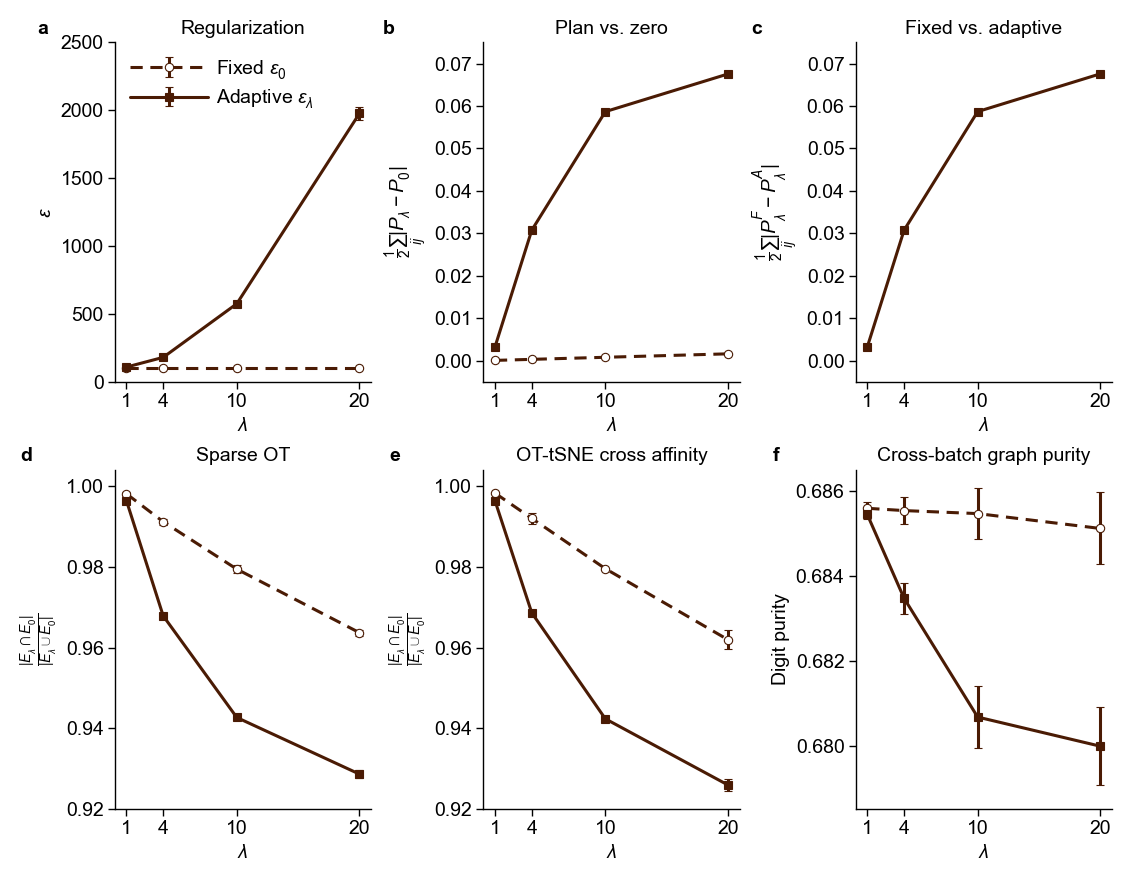

Appendix · projected · rel_reg=1 · mnist_orthogonal_batch_effect__seed0__c70fb5e4


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


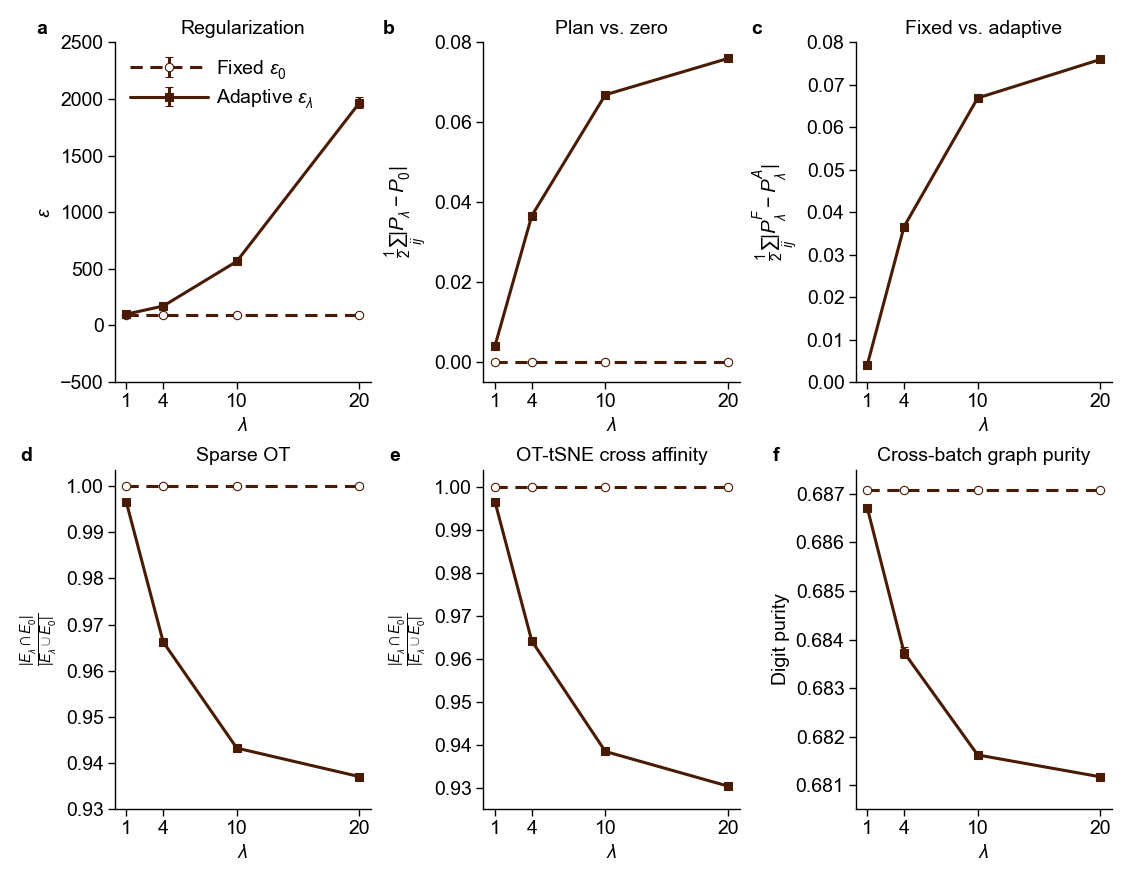

Appendix PNG/PDF files: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__c70fb5e4/figures/appendix_eps_ablation


In [39]:
SAVE_APPENDIX_FIGURES = True
APPENDIX_REL_REG = 1.0
appendix_dir = experiment.run_dir / "figures/appendix_eps_ablation"
for mode in config.data.modes:
    plan_data = cost.loc[(cost["mode"] == mode) & np.isclose(cost.rel_reg, APPENDIX_REL_REG)]
    graph_data = affinity.loc[(affinity["mode"] == mode) & np.isclose(affinity.rel_reg, APPENDIX_REL_REG)]
    fig, axes = plt.subplots(2, 3, figsize=layout.full_width(4.25), layout="constrained")
    specifications = (
        (plan_data, "epsilon", r"$\epsilon$", "Regularization", False),
        (plan_data, "tv_to_lambda0", r"$\frac{1}{2}\sum_{ij}|P_\lambda-P_0|$", "Plan vs. zero", False),
        (plan_data, "fixed_vs_adaptive_tv", r"$\frac{1}{2}\sum_{ij}|P_\lambda^F-P_\lambda^A|$", "Fixed vs. adaptive", False),
        (graph_data, "shared_or_jaccard_to_lambda0", r"$\frac{|E_\lambda\cap E_0|}{|E_\lambda\cup E_0|}$", "Sparse OT", True),
        (graph_data, "ot_tsne_cross_jaccard_to_lambda0", r"$\frac{|E_\lambda\cap E_0|}{|E_\lambda\cup E_0|}$", "OT-tSNE cross affinity", True),
        (graph_data, "eot_shared_or_symmetric_digit_purity", "Digit purity", "Cross-batch graph purity", True),
    )
    for ax, (frame, metric, ylabel, title, bounded) in zip(axes.flat, specifications):
        policy_panel(ax, frame, metric, ylabel, title, bounded=bounded)
        rounded_diagnostic_ylim(ax, probability=bounded)
        if metric in {"shared_or_jaccard_to_lambda0", "ot_tsne_cross_jaccard_to_lambda0"}:
            # Jaccard can equal 1: keep markers/error-bar caps clear of the top boundary.
            lower, upper = ax.get_ylim()
            headroom = .05 * (upper - lower)
            quantum = 5 * 10.0 ** (np.floor(np.log10(headroom)) - 1)
            upper = np.ceil((max(upper, ax.dataLim.ymax) + headroom) / quantum) * quantum
            ax.set_ylim(lower, float(upper))
    axes[0, 0].legend(fontsize=drawing.PANEL_TITLE_PT, handlelength=4)
    for letter, ax, (_, _, _, title, _) in zip("abcdef", axes.flat, specifications):
        drawing.set_panel_title(ax, title, fontsize=drawing.PANEL_TITLE_PT,
            letter=letter, centred=True)
        ax.tick_params(labelsize=drawing.PANEL_TITLE_PT)
        ax.xaxis.label.set_size(drawing.PANEL_TITLE_PT)
        ax.yaxis.label.set_size(drawing.PANEL_TITLE_PT)
    fig.canvas.draw()
    fig.set_layout_engine("none")  # Freeze positions before the paper's title alignment pass.
    drawing.align_panel_titles(fig)
    print(f"Appendix · {mode} · rel_reg=1 · {experiment.run_dir.name}")
    if SAVE_APPENDIX_FIGURES:
        layout.save_figure(fig, f"eps_ablation_{mode}__rel_reg_1", root=appendix_dir,
            formats=("png", "pdf"), preview=False, close=False)
    plt.show()
if SAVE_APPENDIX_FIGURES:
    print(f"Appendix PNG/PDF files: {appendix_dir}")


### Appendix alternative: MNIST and signal-projected control in two rows
The same saved `rel_reg=1` results feed this second layout. Row 1 is MNIST in the original pixel
space; row 2 is the signal-projected control. Columns are regularization, sparsified graph edge
overlap, sparsified graph purity, and total variation against each policy's zero-corruption plan.
The graph is the row/column top-15 union (Sparse OT), not the OT-tSNE cross-block graph.
Edge overlap is Jaccard $|E_\lambda\cap E_0|/|E_\lambda\cup E_0|$; neighbor purity is the equal-batch average of unweighted same-digit neighbor purity
from batch 0 and batch 1, as defined in the symmetric graph-purity subsection above. TV is $\frac12\sum_{ij}|P_\lambda(i,j)-P_0(i,j)|$.
Both policies are shown with mean ± SD over corruption seeds. Titles, tick labels, axis labels,
and lowercase panel letters use the main synthetic figure's 7-point metric-panel size and
canonical panel-ink alignment helper. Column headings appear only above the first row, with
letters at a common height above each row; the upper row keeps x-axis ticks without numbers or λ labels.
The main paper graph-purity panels use the same symmetric definition; embedding metrics are unchanged.


Appendix alternative · MNIST / signal-projected · rel_reg=1 · mnist_orthogonal_batch_effect__seed0__c70fb5e4


Saved second layout: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_orthogonal_batch_effect/mnist_orthogonal_batch_effect__seed0__c70fb5e4/figures/appendix_eps_ablation/eps_ablation_mnist_and_projected__two_rows__rel_reg_1.png


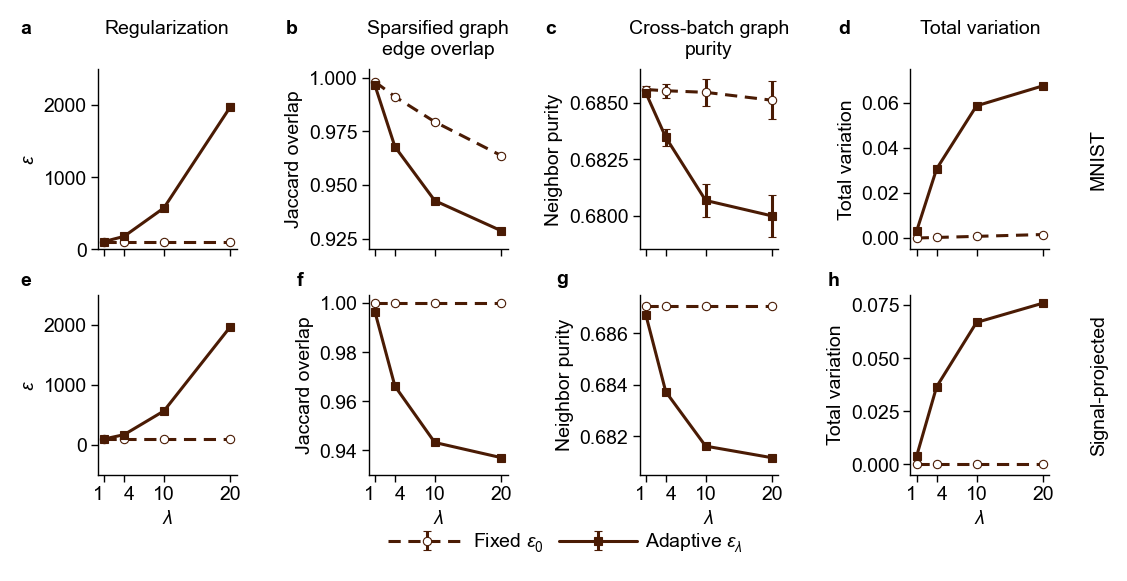

In [40]:
# Second appendix version: retain the existing six-panel figures above.
TWO_ROW_MODES = (("original", "MNIST"), ("projected", "Signal-projected"))
TWO_ROW_COLUMNS = (
    ("epsilon", r"$\epsilon$", "Regularization", False),
    ("shared_or_jaccard_to_lambda0", "Jaccard overlap", "Sparsified graph\nedge overlap", True),
    ("eot_shared_or_symmetric_digit_purity", "Neighbor purity", "Cross-batch graph\npurity", True),
    ("tv_to_lambda0", "Total variation", "Total variation", False),
)
with layout.paper_style(), plt.rc_context({"figure.constrained_layout.use": False}):
    fig, axes = plt.subplots(2, 4, figsize=layout.full_width(2.9), layout=None)
    fig.subplots_adjust(left=.075, right=.94, bottom=.15, top=.85, wspace=.95, hspace=.25)
    for row, (mode, row_label) in enumerate(TWO_ROW_MODES):
        plan_data = cost.loc[(cost["mode"] == mode) & np.isclose(cost.rel_reg, APPENDIX_REL_REG)]
        graph_data = affinity.loc[(affinity["mode"] == mode) & np.isclose(affinity.rel_reg, APPENDIX_REL_REG)]
        for col, (metric, ylabel, title, bounded) in enumerate(TWO_ROW_COLUMNS):
            ax = axes[row, col]
            frame = graph_data if bounded else plan_data
            policy_panel(ax, frame, metric, ylabel, title, bounded=bounded)
            rounded_diagnostic_ylim(ax, probability=bounded)
            if metric == "shared_or_jaccard_to_lambda0":
                lower, upper = ax.get_ylim()
                headroom = .05 * (upper - lower)
                quantum = 5 * 10.0 ** (np.floor(np.log10(headroom)) - 1)
                ax.set_ylim(lower, float(np.ceil((max(upper, ax.dataLim.ymax) + headroom) / quantum) * quantum))
            # Column headings are drawn once below, with a common first-line anchor.
            ax.set_title("")
            ax.tick_params(labelsize=drawing.PANEL_TITLE_PT)
            # Keep the closely spaced λ=1 and λ=4 labels visually separate.
            tick_labels = ax.get_xticklabels()
            tick_labels[0].set_ha("right")
            tick_labels[1].set_ha("left")
            ax.xaxis.label.set_size(drawing.PANEL_TITLE_PT)
            ax.yaxis.label.set_size(drawing.PANEL_TITLE_PT)
            if row == 0:
                ax.tick_params(axis="x", labelbottom=False)  # Keep the tick marks.
                ax.set_xlabel("")
    # Shared policy legend leaves the narrow regularization panels clear.
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False,
        fontsize=drawing.PANEL_TITLE_PT, handlelength=4, bbox_to_anchor=(.50, -.015))
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    inverse = fig.transFigure.inverted()
    heading_top = .935  # Shared first-line anchor for column titles and a–d.
    for col, (_, _, title, _) in enumerate(TWO_ROW_COLUMNS):
        position = axes[0, col].get_position()
        fig.text((position.x0 + position.x1) / 2, heading_top, title,
            ha="center", va="top", multialignment="center",
            fontsize=drawing.PANEL_TITLE_PT)
    for row in range(2):
        letter_top = heading_top if row == 0 else axes[row, 0].get_position().y1 + .04
        for col in range(4):
            ink_left, _ = drawing.panel_ink_span(axes[row, col], renderer, inverse)
            letter = "abcdefgh"[row * 4 + col]
            fig.text(ink_left, letter_top, rf"$\mathbf{{{letter}}}$",
                ha="left", va="top", fontsize=drawing.PANEL_TITLE_PT)
    for row, (_, row_label) in enumerate(TWO_ROW_MODES):
        position = axes[row, 0].get_position()
        fig.text(.985, (position.y0 + position.y1) / 2, row_label, rotation=90,
            ha="center", va="center", fontsize=drawing.PANEL_TITLE_PT)
    print(f"Appendix alternative · MNIST / signal-projected · rel_reg=1 · {experiment.run_dir.name}")
    if SAVE_APPENDIX_FIGURES:
        path = layout.save_figure(fig, "eps_ablation_mnist_and_projected__two_rows__rel_reg_1",
            root=appendix_dir, formats=("png", "pdf"), preview=False, close=False)
        print(f"Saved second layout: {path}")
    plt.show()
